# Supervised transfer of decision trees & random forests

**Synthetic scenario-by-scenario notebook with repeated independent data draws.** Source law: a 7-cluster Gaussian mixture, change in `source_distribution.json` (the JSON describes a *distribution*, not a fixed dataset).

**Model switch:** `MODEL_KIND = 'tree'` shows class-colored tree diagrams comparing relabeling, SER and STRUT; `MODEL_KIND = 'forest'` shows `TransferForestSelector` selection frequencies.

**Protocol for parameter-based transfer:** fit a source tree/forest with source labels, then adapt that pretrained estimator with **labeled target training data**. We also train independent source-only, target-only and naïvely pooled controls.

Every scenario includes a **single-run visualization** and a **repeated-sampling evaluation** (mean ± SD, paired improvement, and forest-selection frequencies when available).


## 0. Imports and one-time model settings

Edit the model switch here. The per-scenario source/target sample sizes are edited **inside each scenario section**, not here.

In [3]:
from pathlib import Path
import sys
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# Works when Jupyter starts in the repository root OR notebooks/.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'source_distribution.json').exists()
             and (p / 'transfer_tree_demo' / '__init__.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Extract the complete project ZIP and open this notebook inside its notebooks/ folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from transfer_tree_demo.distribution import load_distribution, sample_from_distribution
from transfer_tree_demo.scenarios import sample_target, bayes_probability, target_spec
from transfer_tree_demo.plotting import (
    plot_domains, plot_predictions, plot_tree_diff, plot_selection_frequencies, plot_repeated_accuracy
)

# MODEL SELECTION — choose ONE
MODEL_KIND = 'forest'                  # 'forest' or 'tree'
TREE_PARAMS = dict(max_depth=6, min_samples_leaf=5)
FOREST_PARAMS = dict(n_estimators=31, max_depth=4,min_samples_leaf=5)

SER_MAX_DEPTH = 7
LIST_ALG_ARGS = [{},{},{},{"max_depth": SER_MAX_DEPTH},{}]

RANDOM_SEED = 20261102
TREE_PLOT_DEPTH = 4                   # Only affects tree display, not training
PLOT_TREE_DIAGRAMS = True
ALGORITHMS = ['src', 'trgt', 'relabel', 'ser', 'strut']

if MODEL_KIND == 'tree':
    base_estimator = DecisionTreeClassifier(random_state=RANDOM_SEED, **TREE_PARAMS)
elif MODEL_KIND == 'forest':
    base_estimator = RandomForestClassifier(random_state=RANDOM_SEED, **FOREST_PARAMS)
else:
    raise ValueError("MODEL_KIND must be 'tree' or 'forest'")

try:
    from adapt.parameter_based import (
        TransferTreeClassifier, TransferForestClassifier, TransferForestSelector
    )
    HAVE_ADAPT = True
except (ImportError, ModuleNotFoundError) as exc:
    HAVE_ADAPT = False
    print('Native ADAPT unavailable: only real sklearn/Bayes baselines will be run.')
    print(type(exc).__name__, str(exc)[:170])

source_spec = load_distribution(ROOT / 'source_distribution.json')
RESULTS = ROOT / 'results_refactored' / MODEL_KIND
RESULTS.mkdir(parents=True, exist_ok=True)
SCENARIO_CONFIGS = {}    # Stores your visible settings for sensitivity experiments
SCENARIO_SCORES = []
SCENARIO_REPEAT_SUMMARIES = []   # Mean / std for each repeated scenario
print(f'Model: {MODEL_KIND}; native ADAPT available: {HAVE_ADAPT}; clusters: {len(source_spec["labels"])}')

Model: forest; native ADAPT available: True; clusters: 7


### Tree plot legend

- **Blue / orange fill:** majority class among observations reaching that node (including internal nodes).
- **Solid red border:** pruning, expansion or changed split feature.
- **Dashed red border:** same split feature but different threshold.
- **Amber border:** changed majority prediction in a matched leaf.

Changed nodes are matched by left/right decision paths *until the first structural mismatch*. Deeper parts of a pruned or replaced subtree have no reliable one-to-one correspondence. The diagram shows the first `TREE_PLOT_DEPTH` levels only.

## 1. SAME distribution — fresh target draw

Baseline sanity check: the target law is identical to the source law; only the samples differ.

**A. Edit the settings below and rerun this section only.**

In [6]:
SCENARIO = 'same'
SCENARIO_PARAMS = {}
STRENGTH = 1.0
SOURCE_N = 500
TARGET_N = 50
SOURCE_TEST_N = 3000
TARGET_TEST_N = 3000
# Repeat fresh source / target draws from this EXACT scenario distribution.
RUN_REPETITIONS = True
N_REPETITIONS = 10     # Increase to 20–30 for more stable uncertainty estimates
SEED = RANDOM_SEED + 1_000

SCENARIO_CONFIGS[SCENARIO] = dict(
    params=copy.deepcopy(SCENARIO_PARAMS), strength=STRENGTH,
    source_n=SOURCE_N, target_n=TARGET_N,
    source_test_n=SOURCE_TEST_N, target_test_n=TARGET_TEST_N, seed=SEED,
    n_repetitions=N_REPETITIONS, run_repetitions=RUN_REPETITIONS
)
print('Selected configuration:', SCENARIO_CONFIGS[SCENARIO])

Selected configuration: {'params': {}, 'strength': 1.0, 'source_n': 500, 'target_n': 50, 'source_test_n': 3000, 'target_test_n': 3000, 'seed': 20262102, 'n_repetitions': 10, 'run_repetitions': True}


**B. Generate data, visualize both domains, train and evaluate the source-only and target-only baselines.** No transfer occurs in this cell.

Exact target edits:
  • No parameter changes; new independent draws


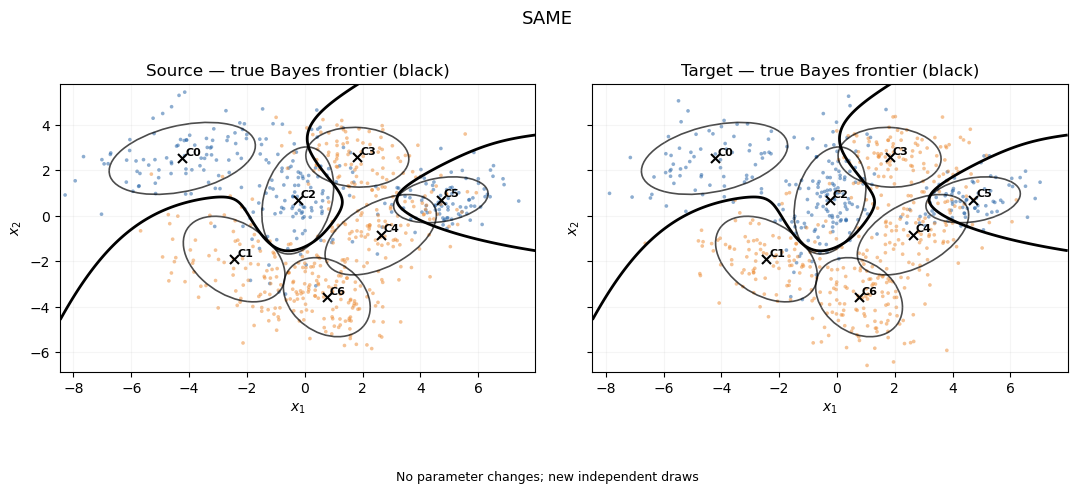

Held-out baseline scores:


,method,source_accuracy,target_accuracy
0,Source-only,0.836,0.829
1,Target-only,0.822,0.816
2,Pooled (no adaptation),0.838,0.833


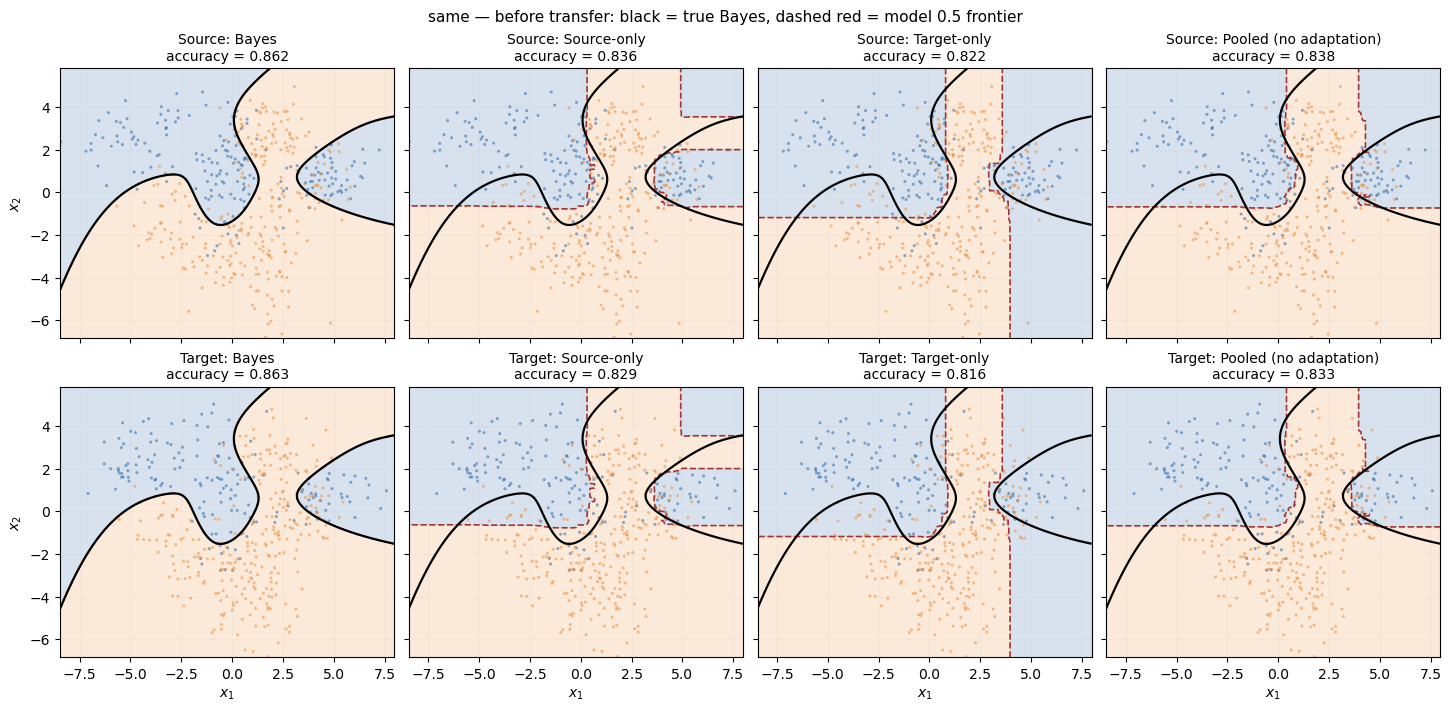

In [8]:
# Independent source and target draws from the saved probability laws.
Xs_train, ys_train, _, cs_train = sample_from_distribution(source_spec, SOURCE_N, seed=SEED)
Xs_test, ys_test, _, cs_test = sample_from_distribution(source_spec, SOURCE_TEST_N, seed=SEED + 1)
Xt_train, yt_train, _, ct_train, target_spec, notes = sample_target(
    source_spec, SCENARIO, TARGET_N, seed=SEED + 2,
    strength=STRENGTH, params=SCENARIO_PARAMS
)
Xt_test, yt_test, _, ct_test, _, _ = sample_target(
    source_spec, SCENARIO, TARGET_TEST_N, seed=SEED + 3,
    strength=STRENGTH, params=SCENARIO_PARAMS
)

print('Exact target edits:')
for note in notes:
    print('  •', note)
plot_domains(Xs_test, ys_test, Xt_test, yt_test, source_spec, target_spec,
             SCENARIO, notes, save=RESULTS / f'{SCENARIO}_01_domains.png')

# Three independent fitted controls; the pooled model is a useful diagnostic.
source_model = clone(base_estimator)
source_model.fit(Xs_train, ys_train)

target_model = clone(base_estimator)
target_model.fit(Xt_train, yt_train)                  # target LABELS are used

pooled_model = clone(base_estimator)
pooled_model.fit(np.vstack([Xs_train, Xt_train]), np.r_[ys_train, yt_train])

baseline_models = {'Source-only': source_model,
                   'Target-only': target_model,
                   'Pooled (no adaptation)': pooled_model}

baseline_scores = []
for label, predictor in baseline_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    baseline_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))
print('Held-out baseline scores:')
display(pd.DataFrame(baseline_scores).round(3))

# Bayes frontier + baseline decision regions, on SOURCE and TARGET.
plot_predictions(baseline_models, Xs_test, ys_test, Xt_test, yt_test,
                 source_spec, target_spec, SCENARIO + ' — before transfer',
                 save=RESULTS / f'{SCENARIO}_02_baselines.png')

**C. Adapt the pretrained source model using labeled target training data; evaluate on untouched test samples.** These are the actual ADAPT calls, not helper wrappers.

,scenario,method,source_accuracy,target_accuracy
0,same,Source-only,0.836,0.829
1,same,Target-only,0.822,0.816
2,same,Pooled (no adaptation),0.838,0.833
3,same,RELABEL,0.811,0.799
4,same,SER,0.821,0.817
5,same,STRUT,0.816,0.805
6,same,Forest selector,0.837,0.834


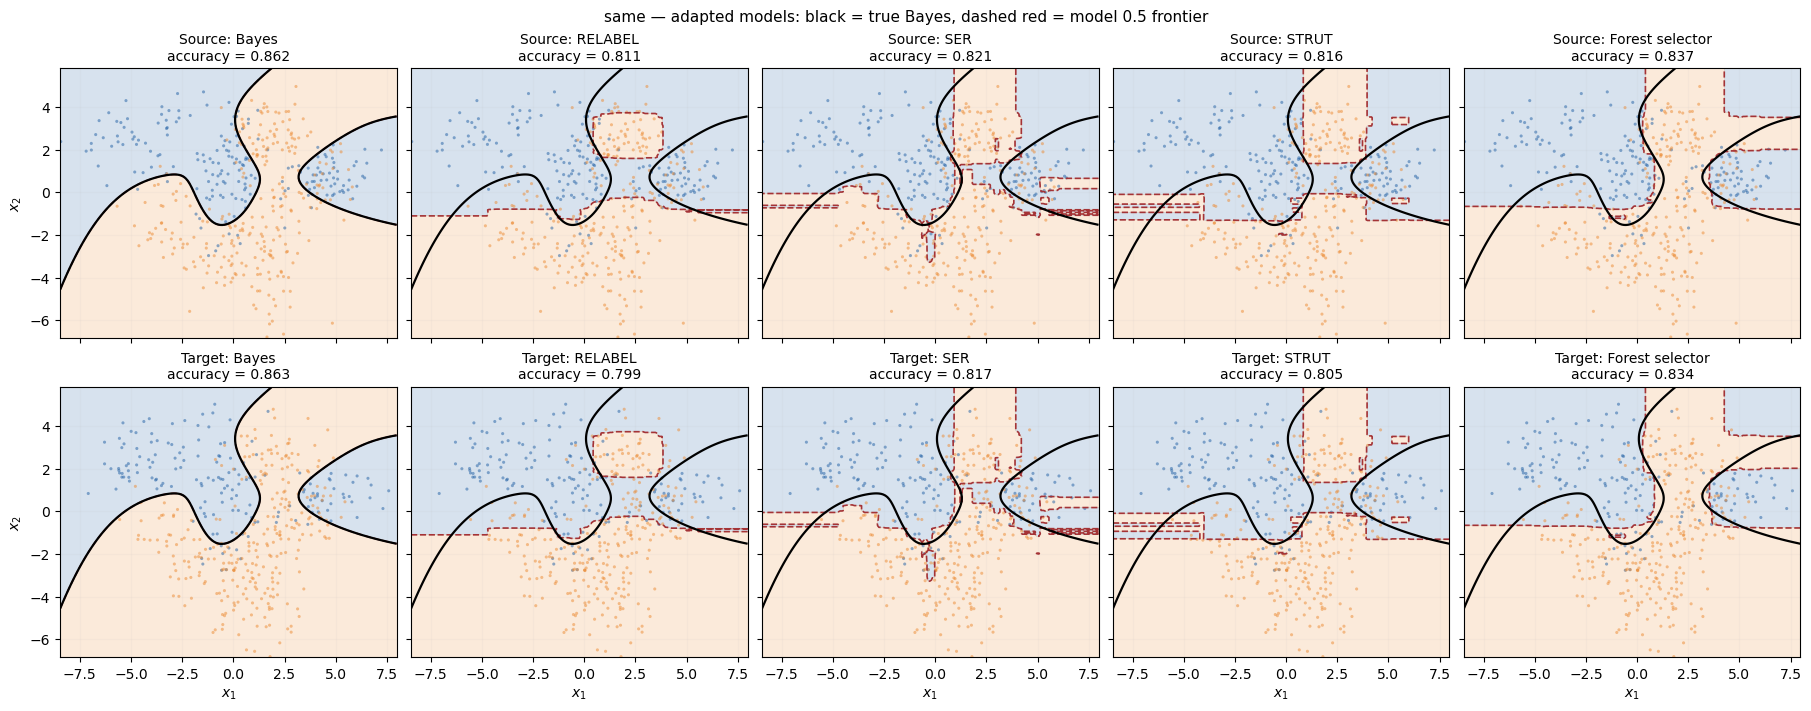

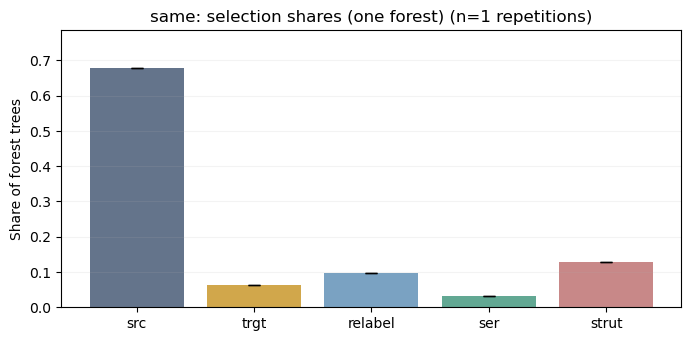

src=keep source; trgt=learn target; relab=change leaves; ser=expand/reduce; strut=adjust split conditions.


In [13]:
transferred_models = {}
selection_indices = None

if HAVE_ADAPT:
    for algorithm in ('relabel', 'ser', 'strut'):
        try:
            TransferClass = (TransferTreeClassifier if MODEL_KIND == 'tree'
                             else TransferForestClassifier)
            adapted = TransferClass(
                estimator=copy.deepcopy(source_model),
                algo=algorithm, copy=True, verbose=0, random_state=RANDOM_SEED
            )

            fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )
            
            adapted.fit(Xt_train, yt_train, **fit_params)  
            transferred_models[algorithm.upper()] = adapted.estimator_
        except Exception as exc:
            print(f'{algorithm.upper()} failed: {type(exc).__name__}: {exc}')

    if MODEL_KIND == 'forest':
        try:
            selector = TransferForestSelector(
                estimator=copy.deepcopy(source_model),
                algorithms=ALGORITHMS, copy=True, verbose=0,
                random_state=RANDOM_SEED,
                list_alg_args=LIST_ALG_ARGS
            )
            selector.model_selection(Xt_train, yt_train,
                                     score_type='auc', oob_=True)
            transferred_models['Forest selector'] = selector.STRF_model.estimator_
            selection_indices = np.asarray(selector.STRF_indexes, dtype=int)
        except Exception as exc:
            print(f'Forest selector failed: {type(exc).__name__}: {exc}')
else:
    print('ADAPT missing: relabel/SER/STRUT/selector NOT evaluated.')

transfer_scores = []
for label, predictor in transferred_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    transfer_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))

all_case_scores = pd.DataFrame(baseline_scores + transfer_scores)
all_case_scores.insert(0, 'scenario', SCENARIO)
SCENARIO_SCORES.extend(all_case_scores.to_dict('records'))
display(all_case_scores.round(3))
all_case_scores.to_csv(RESULTS / f'{SCENARIO}_scores.csv', index=False)

if transferred_models:
    plot_predictions(transferred_models, Xs_test, ys_test, Xt_test, yt_test,
                     source_spec, target_spec, SCENARIO + ' — adapted models',
                     save=RESULTS / f'{SCENARIO}_03_transferred.png')

    # Change to plot the training data :
    #plot_predictions(transferred_models, Xs_test, ys_test, Xt_train, yt_train,
    #                 source_spec, target_spec, SCENARIO + ' — adapted models',
    #                 save=RESULTS / f'{SCENARIO}_03_transferred.png')

if MODEL_KIND == 'tree' and PLOT_TREE_DIAGRAMS:
    for algorithm, predictor in transferred_models.items():
        if hasattr(predictor, 'tree_'):
            changes = plot_tree_diff(source_model, predictor,
                title=f'{SCENARIO}: source → {algorithm}',
                max_depth=TREE_PLOT_DEPTH,
                save=RESULTS / f'{SCENARIO}_{algorithm.lower()}_tree.png')
            print(f'{algorithm}: {len(changes)} matched paths changed; ' +
                  'solid red=structure, dashed red=threshold, amber=leaf class')

if MODEL_KIND == 'forest' and selection_indices is not None:
    plot_selection_frequencies([selection_indices], ALGORITHMS,
        f'{SCENARIO}: selection shares (one forest)',
        save=RESULTS / f'{SCENARIO}_selector.png')
    print('src=keep source; trgt=learn target; relab=change leaves; '
          'ser=expand/reduce; strut=adjust split conditions.')

**D. Repeat the experiment on fresh samples from the same distributions.** Change `N_REPETITIONS` in this scenario’s settings. Each repetition redraws source/target training **and** held-out test data, fits all baseline and ADAPT models from scratch, and computes paired target scores. The single-run prediction figures above remain as an illustration; the table below is the average over repetitions. Forest method-selection bars are also averaged over repetitions.

same: 10 newly sampled training/test realizations
Held-out accuracy: mean ± SD across independent draws


,method,n_runs,source_mean,source_std,target_mean,target_std
0,Forest selector,10,0.829,0.013,0.830,0.013
1,Pooled (no adaptation),10,0.835,0.011,0.836,0.009
2,RELABEL,10,0.814,0.027,0.815,0.026
3,SER,10,0.792,0.024,0.789,0.024
4,STRUT,10,0.798,0.022,0.796,0.027
5,Source-only,10,0.836,0.010,0.838,0.009
6,Target-only,10,0.775,0.044,0.774,0.044


Paired transfer improvements; > 0 means better than BOTH baselines in that repetition


,method,mean_gain_vs_best_baseline,sd_gain,fraction_positive,mean_gain_vs_pooling,n_paired
0,Forest selector,-0.008,0.012,0.4,-0.006,10
1,RELABEL,-0.023,0.023,0.1,-0.021,10
2,SER,-0.049,0.020,0.0,-0.047,10
3,STRUT,-0.042,0.022,0.0,-0.040,10


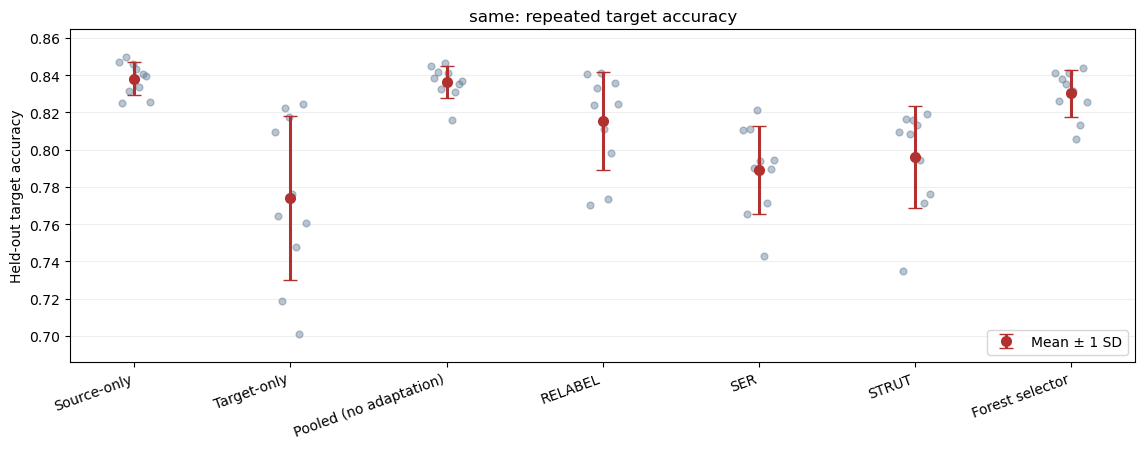

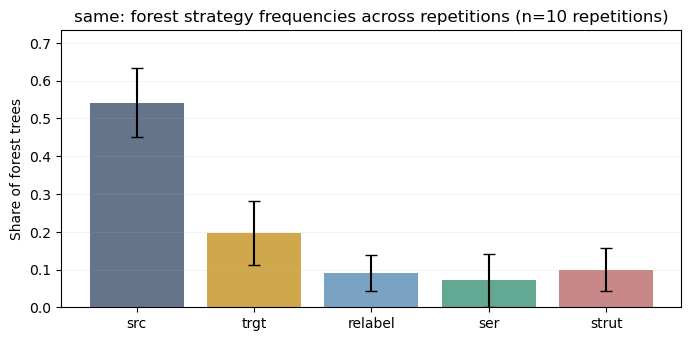

In [16]:
# Restore this section's recorded settings, even if other sections ran afterward.
SCENARIO = 'same'
_rep_cfg = SCENARIO_CONFIGS[SCENARIO]
SCENARIO_PARAMS = copy.deepcopy(_rep_cfg['params'])
STRENGTH = _rep_cfg['strength']
SOURCE_N, TARGET_N = _rep_cfg['source_n'], _rep_cfg['target_n']
SOURCE_TEST_N, TARGET_TEST_N = _rep_cfg['source_test_n'], _rep_cfg['target_test_n']
SEED = _rep_cfg['seed']
RUN_REPETITIONS = _rep_cfg['run_repetitions']
N_REPETITIONS = _rep_cfg['n_repetitions']

# Independent draws from the SAME fixed source and target distributions.
# This is separate from the illustrative single-run plots above.
# Every repetition re-draws BOTH labeled training sets and BOTH held-out test sets.
repeated_rows = []
repeated_selections = []
failed_adapt = []

if RUN_REPETITIONS:
    for rep in range(N_REPETITIONS):
        rep_seed = SEED + 100_000 + 10 * rep

        Xs_rep, ys_rep, _, _ = sample_from_distribution(
            source_spec, SOURCE_N, seed=rep_seed)
        Xs_eval, ys_eval, _, _ = sample_from_distribution(
            source_spec, SOURCE_TEST_N, seed=rep_seed + 1)
        Xt_rep, yt_rep, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_N, seed=rep_seed + 2,
            strength=STRENGTH, params=SCENARIO_PARAMS)
        Xt_eval, yt_eval, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_TEST_N, seed=rep_seed + 3,
            strength=STRENGTH, params=SCENARIO_PARAMS)

        # Baseline fits — exactly the SAME datasets and test samples per repetition.
        src_rep_model = clone(base_estimator)
        src_rep_model.fit(Xs_rep, ys_rep)
        tgt_rep_model = clone(base_estimator)
        tgt_rep_model.fit(Xt_rep, yt_rep)
        pooled_rep_model = clone(base_estimator)
        pooled_rep_model.fit(np.vstack((Xs_rep, Xt_rep)), np.r_[ys_rep, yt_rep])
        rep_models = {
            'Source-only': src_rep_model,
            'Target-only': tgt_rep_model,
            'Pooled (no adaptation)': pooled_rep_model,
        }

        # Supervised ADAPT methods — use the FITTED SOURCE model and labeled TARGET data.
        if HAVE_ADAPT:
            for algo in ('relabel', 'ser', 'strut'):
                try:
                    cls = TransferTreeClassifier if MODEL_KIND == 'tree' else TransferForestClassifier
                    adapted = cls(estimator=copy.deepcopy(src_rep_model), algo=algo,
                                  copy=True, verbose=0, random_state=RANDOM_SEED)
                    
                    fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )            
                    adapted.fit(Xt_rep, yt_rep, **fit_params) 
                    
                    rep_models[algo.upper()] = adapted.estimator_
                except Exception as exc:
                    failed_adapt.append((rep, algo, type(exc).__name__, str(exc)[:120]))

            if MODEL_KIND == 'forest':
                try:
                    selector = TransferForestSelector(
                        estimator=copy.deepcopy(src_rep_model), algorithms=ALGORITHMS,
                        copy=True, verbose=0, random_state=RANDOM_SEED,list_alg_args=LIST_ALG_ARGS)
                    selector.model_selection(Xt_rep, yt_rep, score_type='auc', oob_=True)
                    rep_models['Forest selector'] = selector.STRF_model.estimator_
                    repeated_selections.append(np.asarray(selector.STRF_indexes, dtype=int))
                except Exception as exc:
                    failed_adapt.append((rep, 'selector', type(exc).__name__, str(exc)[:120]))

        # Paired evaluation: all methods share each repetition's held-out samples.
        for name, fitted_model in rep_models.items():
            repeated_rows.append({
                'scenario': SCENARIO, 'rep': rep, 'seed': rep_seed, 'method': name,
                'source_accuracy': accuracy_score(ys_eval, fitted_model.predict(Xs_eval)),
                'target_accuracy': accuracy_score(yt_eval, fitted_model.predict(Xt_eval)),
            })

    repeated_df = pd.DataFrame(repeated_rows)
    repeated_df.to_csv(RESULTS / f'{SCENARIO}_repeated_scores.csv', index=False)

    # Mean ± SD across random draws; these are NOT scores from the example plots.
    repeated_summary = (repeated_df.groupby('method')
        .agg(n_runs=('target_accuracy', 'count'),
             source_mean=('source_accuracy', 'mean'),
             source_std=('source_accuracy', 'std'),
             target_mean=('target_accuracy', 'mean'),
             target_std=('target_accuracy', 'std'))
        .reset_index())

    # Per-repetition gain over the better of source-only and target-only.
    paired = repeated_df.pivot(index='rep', columns='method', values='target_accuracy')
    best_base = paired[['Source-only', 'Target-only']].max(axis=1)
    gain_rows = []
    for name in paired.columns:
        if name in ('Source-only', 'Target-only', 'Pooled (no adaptation)'):
            continue
        gain = (paired[name] - best_base).dropna()
        pool_gain = (paired[name] - paired['Pooled (no adaptation)']).dropna()
        gain_rows.append({
            'method': name, 'mean_gain_vs_best_baseline': gain.mean(),
            'sd_gain': gain.std(), 'fraction_positive': (gain > 0).mean(),
            'mean_gain_vs_pooling': pool_gain.mean(), 'n_paired': len(gain),
        })
    gains_df = pd.DataFrame(gain_rows)

    print(f'{SCENARIO}: {N_REPETITIONS} newly sampled training/test realizations')
    print('Held-out accuracy: mean ± SD across independent draws')
    display(repeated_summary.round(3))
    if not gains_df.empty:
        print('Paired transfer improvements; > 0 means better than BOTH baselines in that repetition')
        display(gains_df.round(3))
        gains_df.to_csv(RESULTS / f'{SCENARIO}_paired_gains.csv', index=False)
    # Replace this section's previous summary when rerunning just this block.
    SCENARIO_REPEAT_SUMMARIES[:] = [r for r in SCENARIO_REPEAT_SUMMARIES
                                    if r['scenario'] != SCENARIO]
    SCENARIO_REPEAT_SUMMARIES.extend(
        [dict(scenario=SCENARIO, **row) for row in repeated_summary.to_dict('records')])

    plot_repeated_accuracy(repeated_df, title=f'{SCENARIO}: repeated target accuracy',
        save=RESULTS / f'{SCENARIO}_04_repeated_accuracy.png')

    if MODEL_KIND == 'forest' and repeated_selections:
        plot_selection_frequencies(repeated_selections, ALGORITHMS,
            f'{SCENARIO}: forest strategy frequencies across repetitions',
            save=RESULTS / f'{SCENARIO}_05_repeated_selector.png')

    if failed_adapt:
        print(f'ADAPT fitting failures: {len(failed_adapt)}. First examples:')
        display(pd.DataFrame(failed_adapt, columns=['rep','algo','error_type','message']).head(5))
else:
    print('Repetitions disabled for this scenario. Set RUN_REPETITIONS=True above.')


# 2. Strict covariate shift

Feature-only acceptance $a(x)$ changes $P(X)$ but keeps $P(Y | X)$ invariant.

**A. Edit the settings below and rerun this section only.**

In [18]:
SCENARIO = 'covariate'

SCENARIO_PARAMS = {
    "acceptance_floor": 0.1,
    "acceptance_scale": 0.85,
    "boundary_width": 0.2,
}

STRENGTH = 1.0

SOURCE_N = 500
TARGET_N = 50
SOURCE_TEST_N = 3000
TARGET_TEST_N = 3000

RUN_REPETITIONS = True
N_REPETITIONS = 10     # Increase to 20–30 for more stable uncertainty estimates
SEED = RANDOM_SEED + 2_000

SCENARIO_CONFIGS[SCENARIO] = dict(
    params=copy.deepcopy(SCENARIO_PARAMS), strength=STRENGTH,
    source_n=SOURCE_N, target_n=TARGET_N,
    source_test_n=SOURCE_TEST_N, target_test_n=TARGET_TEST_N, seed=SEED,
    n_repetitions=N_REPETITIONS, run_repetitions=RUN_REPETITIONS
)
print('Selected configuration:', SCENARIO_CONFIGS[SCENARIO])

Selected configuration: {'params': {'acceptance_floor': 0.1, 'acceptance_scale': 0.85, 'boundary_width': 0.2}, 'strength': 1.0, 'source_n': 500, 'target_n': 50, 'source_test_n': 3000, 'target_test_n': 3000, 'seed': 20263102, 'n_repetitions': 10, 'run_repetitions': True}


**B. Generate data, visualize both domains, train and evaluate the source-only and target-only baselines.** No transfer occurs in this cell.

Exact target edits:
  • Boundary-focused covariate shift: width=0.200
  • Acceptance floor=0.100, scale=0.850
  • P_T(Y|X) = P_S(Y|X)


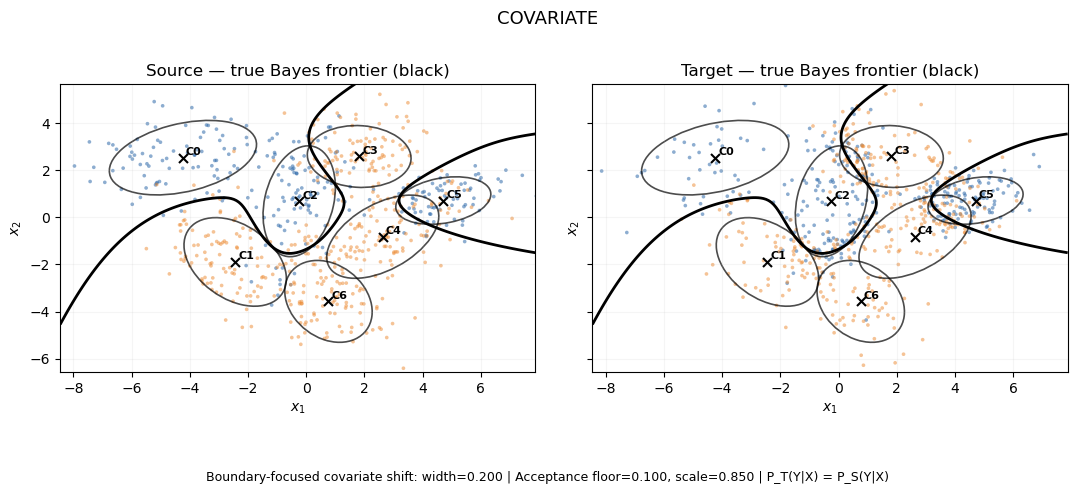

Held-out baseline scores:


,method,source_accuracy,target_accuracy
0,Source-only,0.848,0.705
1,Target-only,0.805,0.681
2,Pooled (no adaptation),0.853,0.724


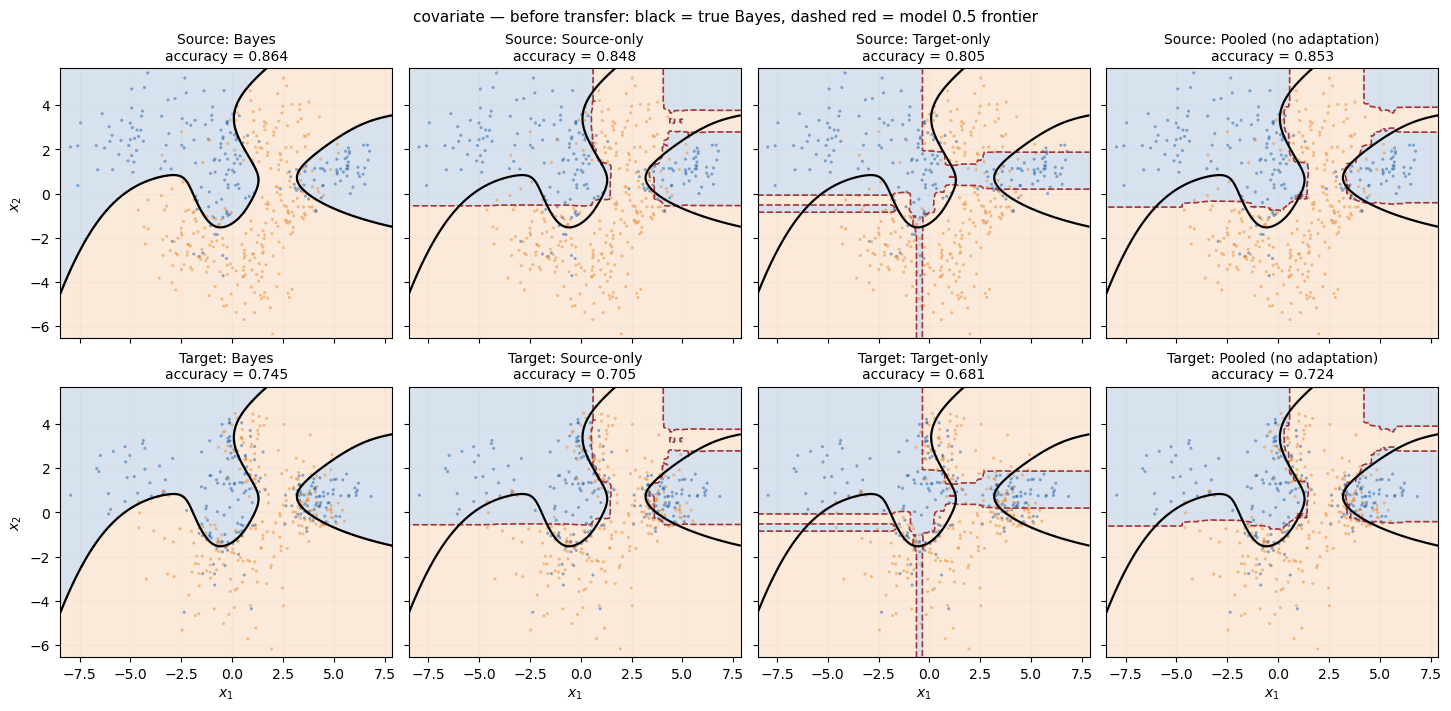

In [21]:
# Independent source and target draws from the saved probability laws.
Xs_train, ys_train, _, cs_train = sample_from_distribution(source_spec, SOURCE_N, seed=SEED)
Xs_test, ys_test, _, cs_test = sample_from_distribution(source_spec, SOURCE_TEST_N, seed=SEED + 1)
Xt_train, yt_train, _, ct_train, target_spec, notes = sample_target(
    source_spec, SCENARIO, TARGET_N, seed=SEED + 2,
    strength=STRENGTH, params=SCENARIO_PARAMS
)
Xt_test, yt_test, _, ct_test, _, _ = sample_target(
    source_spec, SCENARIO, TARGET_TEST_N, seed=SEED + 3,
    strength=STRENGTH, params=SCENARIO_PARAMS
)

print('Exact target edits:')
for note in notes:
    print('  •', note)
plot_domains(Xs_test, ys_test, Xt_test, yt_test, source_spec, target_spec,
             SCENARIO, notes, save=RESULTS / f'{SCENARIO}_01_domains.png')

# Three independent fitted controls; the pooled model is a useful diagnostic.
source_model = clone(base_estimator)
source_model.fit(Xs_train, ys_train)

target_model = clone(base_estimator)
target_model.fit(Xt_train, yt_train)                  # target LABELS are used

pooled_model = clone(base_estimator)
pooled_model.fit(np.vstack([Xs_train, Xt_train]), np.r_[ys_train, yt_train])

baseline_models = {'Source-only': source_model,
                   'Target-only': target_model,
                   'Pooled (no adaptation)': pooled_model}

baseline_scores = []
for label, predictor in baseline_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    baseline_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))
print('Held-out baseline scores:')
display(pd.DataFrame(baseline_scores).round(3))

# Bayes frontier + baseline decision regions, on SOURCE and TARGET.
plot_predictions(baseline_models, Xs_test, ys_test, Xt_test, yt_test,
                 source_spec, target_spec, SCENARIO + ' — before transfer',
                 save=RESULTS / f'{SCENARIO}_02_baselines.png')

**C. Adapt the pretrained source model using labeled target training data; evaluate on untouched test samples.** These are the actual ADAPT calls, not helper wrappers.

,scenario,method,source_accuracy,target_accuracy
0,covariate,Source-only,0.848,0.705
1,covariate,Target-only,0.805,0.681
2,covariate,Pooled (no adaptation),0.853,0.724
3,covariate,RELABEL,0.824,0.701
4,covariate,SER,0.789,0.679
5,covariate,STRUT,0.776,0.669
6,covariate,Forest selector,0.833,0.714


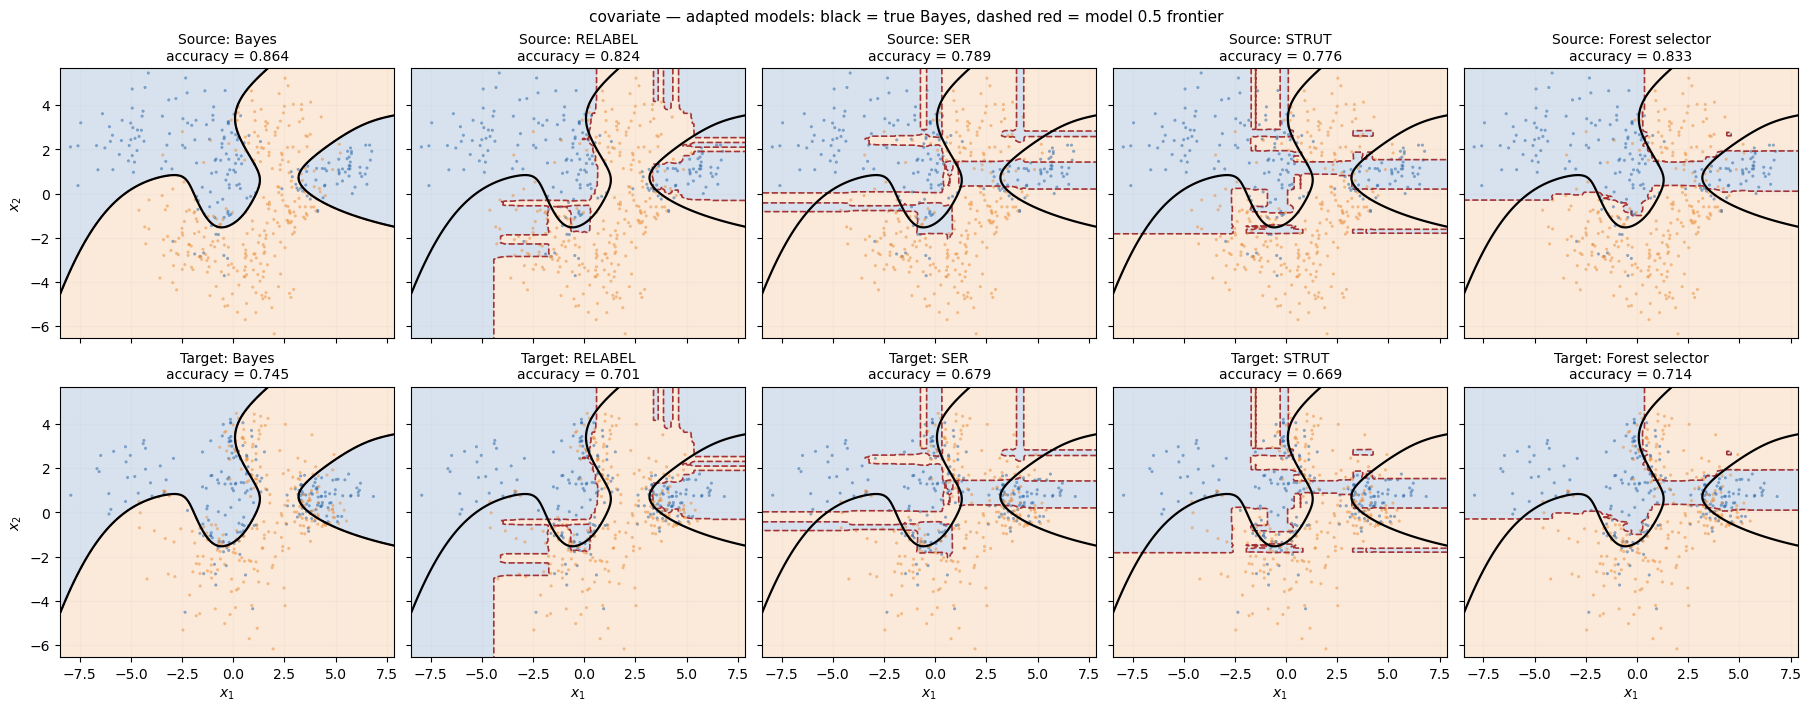

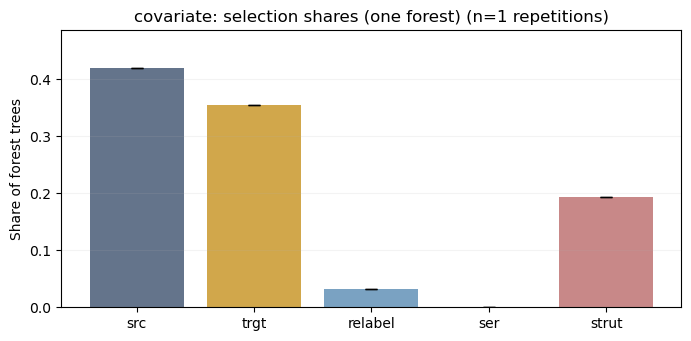

src=keep source; trgt=learn target; relab=change leaves; ser=expand/reduce; strut=adjust split conditions.


In [24]:
transferred_models = {}
selection_indices = None

if HAVE_ADAPT:
    for algorithm in ('relabel', 'ser', 'strut'):
        try:
            TransferClass = (TransferTreeClassifier if MODEL_KIND == 'tree'
                             else TransferForestClassifier)
            adapted = TransferClass(
                estimator=copy.deepcopy(source_model),
                algo=algorithm, copy=True, verbose=0, random_state=RANDOM_SEED
            )
            fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )
            
            adapted.fit(Xt_train, yt_train, **fit_params) 
            transferred_models[algorithm.upper()] = adapted.estimator_
        except Exception as exc:
            print(f'{algorithm.upper()} failed: {type(exc).__name__}: {exc}')

    if MODEL_KIND == 'forest':
        try:
            selector = TransferForestSelector(
                estimator=copy.deepcopy(source_model),
                algorithms=ALGORITHMS, copy=True, verbose=0,
                random_state=RANDOM_SEED
            )
            selector.model_selection(Xt_train, yt_train,
                                     score_type='auc', oob_=True)
            transferred_models['Forest selector'] = selector.STRF_model.estimator_
            selection_indices = np.asarray(selector.STRF_indexes, dtype=int)
        except Exception as exc:
            print(f'Forest selector failed: {type(exc).__name__}: {exc}')
else:
    print('ADAPT missing: relabel/SER/STRUT/selector NOT evaluated.')

transfer_scores = []
for label, predictor in transferred_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    transfer_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))

all_case_scores = pd.DataFrame(baseline_scores + transfer_scores)
all_case_scores.insert(0, 'scenario', SCENARIO)
SCENARIO_SCORES.extend(all_case_scores.to_dict('records'))
display(all_case_scores.round(3))
all_case_scores.to_csv(RESULTS / f'{SCENARIO}_scores.csv', index=False)

if transferred_models:
    plot_predictions(transferred_models, Xs_test, ys_test, Xt_test, yt_test,
                     source_spec, target_spec, SCENARIO + ' — adapted models',
                     save=RESULTS / f'{SCENARIO}_03_transferred.png')

    # Change to plot the training data :
    #plot_predictions(transferred_models, Xs_test, ys_test, Xt_train, yt_train,
    #                 source_spec, target_spec, SCENARIO + ' — adapted models',
    #                 save=RESULTS / f'{SCENARIO}_03_transferred.png')

if MODEL_KIND == 'tree' and PLOT_TREE_DIAGRAMS:
    for algorithm, predictor in transferred_models.items():
        if hasattr(predictor, 'tree_'):
            changes = plot_tree_diff(source_model, predictor,
                title=f'{SCENARIO}: source → {algorithm}',
                max_depth=TREE_PLOT_DEPTH,
                save=RESULTS / f'{SCENARIO}_{algorithm.lower()}_tree.png')
            print(f'{algorithm}: {len(changes)} matched paths changed; ' +
                  'solid red=structure, dashed red=threshold, amber=leaf class')

if MODEL_KIND == 'forest' and selection_indices is not None:
    plot_selection_frequencies([selection_indices], ALGORITHMS,
        f'{SCENARIO}: selection shares (one forest)',
        save=RESULTS / f'{SCENARIO}_selector.png')
    print('src=keep source; trgt=learn target; relab=change leaves; '
          'ser=expand/reduce; strut=adjust split conditions.')

**D. Repeat the experiment on fresh samples from the same distributions.** Change `N_REPETITIONS` in this scenario’s settings. Each repetition redraws source/target training **and** held-out test data, fits all baseline and ADAPT models from scratch, and computes paired target scores. The single-run prediction figures above remain as an illustration; the table below is the average over repetitions. Forest method-selection bars are also averaged over repetitions.

covariate: 10 newly sampled training/test realizations
Held-out accuracy: mean ± SD across independent draws


,method,n_runs,source_mean,source_std,target_mean,target_std
0,Forest selector,10,0.830,0.012,0.704,0.015
1,Pooled (no adaptation),10,0.840,0.009,0.712,0.006
2,RELABEL,10,0.800,0.033,0.676,0.027
3,SER,10,0.771,0.030,0.661,0.018
4,STRUT,10,0.768,0.039,0.655,0.026
5,Source-only,10,0.837,0.009,0.711,0.011
6,Target-only,10,0.751,0.056,0.644,0.030


Paired transfer improvements; > 0 means better than BOTH baselines in that repetition


,method,mean_gain_vs_best_baseline,sd_gain,fraction_positive,mean_gain_vs_pooling,n_paired
0,Forest selector,-0.007,0.018,0.3,-0.008,10
1,RELABEL,-0.035,0.022,0.1,-0.036,10
2,SER,-0.051,0.017,0.0,-0.052,10
3,STRUT,-0.057,0.024,0.0,-0.057,10


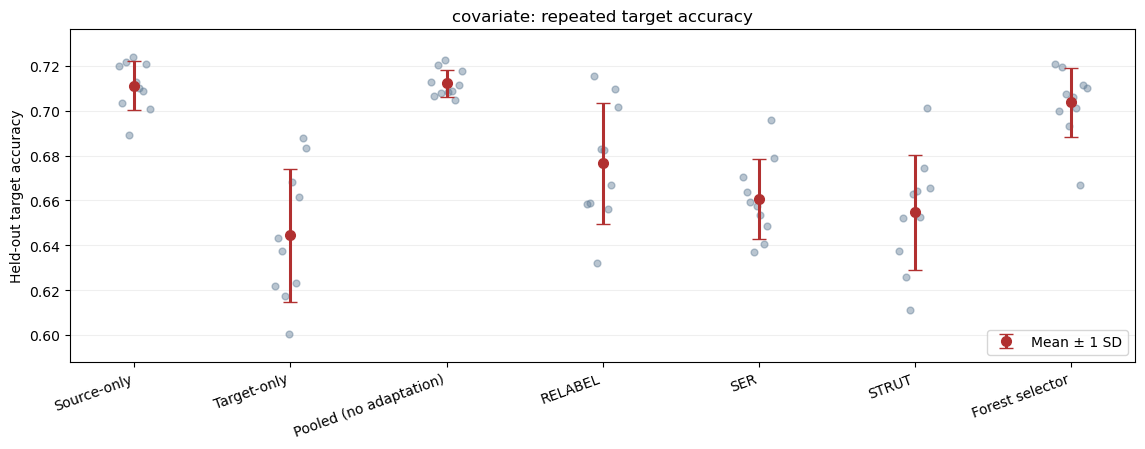

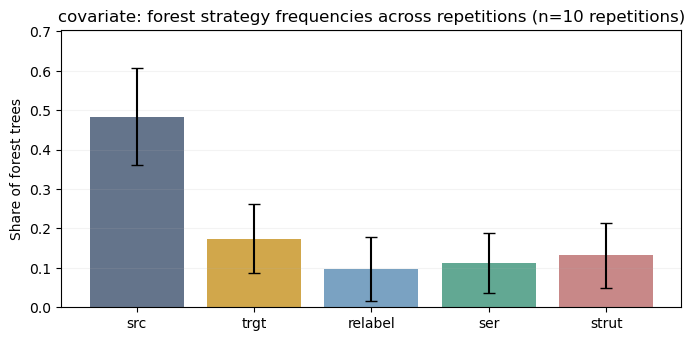

In [27]:
# Restore this section's recorded settings, even if other sections ran afterward.
SCENARIO = 'covariate'
_rep_cfg = SCENARIO_CONFIGS[SCENARIO]
SCENARIO_PARAMS = copy.deepcopy(_rep_cfg['params'])
STRENGTH = _rep_cfg['strength']
SOURCE_N, TARGET_N = _rep_cfg['source_n'], _rep_cfg['target_n']
SOURCE_TEST_N, TARGET_TEST_N = _rep_cfg['source_test_n'], _rep_cfg['target_test_n']
SEED = _rep_cfg['seed']
RUN_REPETITIONS = _rep_cfg['run_repetitions']
N_REPETITIONS = _rep_cfg['n_repetitions']

# Independent draws from the SAME fixed source and target distributions.
# This is separate from the illustrative single-run plots above.
# Every repetition re-draws BOTH labeled training sets and BOTH held-out test sets.
repeated_rows = []
repeated_selections = []
failed_adapt = []

if RUN_REPETITIONS:
    for rep in range(N_REPETITIONS):
        rep_seed = SEED + 100_000 + 10 * rep

        Xs_rep, ys_rep, _, _ = sample_from_distribution(
            source_spec, SOURCE_N, seed=rep_seed)
        Xs_eval, ys_eval, _, _ = sample_from_distribution(
            source_spec, SOURCE_TEST_N, seed=rep_seed + 1)
        Xt_rep, yt_rep, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_N, seed=rep_seed + 2,
            strength=STRENGTH, params=SCENARIO_PARAMS)
        Xt_eval, yt_eval, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_TEST_N, seed=rep_seed + 3,
            strength=STRENGTH, params=SCENARIO_PARAMS)

        # Baseline fits — exactly the SAME datasets and test samples per repetition.
        src_rep_model = clone(base_estimator)
        src_rep_model.fit(Xs_rep, ys_rep)
        tgt_rep_model = clone(base_estimator)
        tgt_rep_model.fit(Xt_rep, yt_rep)
        pooled_rep_model = clone(base_estimator)
        pooled_rep_model.fit(np.vstack((Xs_rep, Xt_rep)), np.r_[ys_rep, yt_rep])
        rep_models = {
            'Source-only': src_rep_model,
            'Target-only': tgt_rep_model,
            'Pooled (no adaptation)': pooled_rep_model,
        }

        # Supervised ADAPT methods — use the FITTED SOURCE model and labeled TARGET data.
        if HAVE_ADAPT:
            for algo in ('relabel', 'ser', 'strut'):
                try:
                    cls = TransferTreeClassifier if MODEL_KIND == 'tree' else TransferForestClassifier
                    adapted = cls(estimator=copy.deepcopy(src_rep_model), algo=algo,
                                  copy=True, verbose=0, random_state=RANDOM_SEED)
                    fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )            
                    adapted.fit(Xt_rep, yt_rep, **fit_params) 
                    rep_models[algo.upper()] = adapted.estimator_
                except Exception as exc:
                    failed_adapt.append((rep, algo, type(exc).__name__, str(exc)[:120]))

            if MODEL_KIND == 'forest':
                try:
                    selector = TransferForestSelector(
                        estimator=copy.deepcopy(src_rep_model), algorithms=ALGORITHMS,
                        copy=True, verbose=0, random_state=RANDOM_SEED,list_alg_args=LIST_ALG_ARGS)
                    selector.model_selection(Xt_rep, yt_rep, score_type='auc', oob_=True)
                    rep_models['Forest selector'] = selector.STRF_model.estimator_
                    repeated_selections.append(np.asarray(selector.STRF_indexes, dtype=int))
                except Exception as exc:
                    failed_adapt.append((rep, 'selector', type(exc).__name__, str(exc)[:120]))

        # Paired evaluation: all methods share each repetition's held-out samples.
        for name, fitted_model in rep_models.items():
            repeated_rows.append({
                'scenario': SCENARIO, 'rep': rep, 'seed': rep_seed, 'method': name,
                'source_accuracy': accuracy_score(ys_eval, fitted_model.predict(Xs_eval)),
                'target_accuracy': accuracy_score(yt_eval, fitted_model.predict(Xt_eval)),
            })

    repeated_df = pd.DataFrame(repeated_rows)
    repeated_df.to_csv(RESULTS / f'{SCENARIO}_repeated_scores.csv', index=False)

    # Mean ± SD across random draws; these are NOT scores from the example plots.
    repeated_summary = (repeated_df.groupby('method')
        .agg(n_runs=('target_accuracy', 'count'),
             source_mean=('source_accuracy', 'mean'),
             source_std=('source_accuracy', 'std'),
             target_mean=('target_accuracy', 'mean'),
             target_std=('target_accuracy', 'std'))
        .reset_index())

    # Per-repetition gain over the better of source-only and target-only.
    paired = repeated_df.pivot(index='rep', columns='method', values='target_accuracy')
    best_base = paired[['Source-only', 'Target-only']].max(axis=1)
    gain_rows = []
    for name in paired.columns:
        if name in ('Source-only', 'Target-only', 'Pooled (no adaptation)'):
            continue
        gain = (paired[name] - best_base).dropna()
        pool_gain = (paired[name] - paired['Pooled (no adaptation)']).dropna()
        gain_rows.append({
            'method': name, 'mean_gain_vs_best_baseline': gain.mean(),
            'sd_gain': gain.std(), 'fraction_positive': (gain > 0).mean(),
            'mean_gain_vs_pooling': pool_gain.mean(), 'n_paired': len(gain),
        })
    gains_df = pd.DataFrame(gain_rows)

    print(f'{SCENARIO}: {N_REPETITIONS} newly sampled training/test realizations')
    print('Held-out accuracy: mean ± SD across independent draws')
    display(repeated_summary.round(3))
    if not gains_df.empty:
        print('Paired transfer improvements; > 0 means better than BOTH baselines in that repetition')
        display(gains_df.round(3))
        gains_df.to_csv(RESULTS / f'{SCENARIO}_paired_gains.csv', index=False)
    # Replace this section's previous summary when rerunning just this block.
    SCENARIO_REPEAT_SUMMARIES[:] = [r for r in SCENARIO_REPEAT_SUMMARIES
                                    if r['scenario'] != SCENARIO]
    SCENARIO_REPEAT_SUMMARIES.extend(
        [dict(scenario=SCENARIO, **row) for row in repeated_summary.to_dict('records')])

    plot_repeated_accuracy(repeated_df, title=f'{SCENARIO}: repeated target accuracy',
        save=RESULTS / f'{SCENARIO}_04_repeated_accuracy.png')

    if MODEL_KIND == 'forest' and repeated_selections:
        plot_selection_frequencies(repeated_selections, ALGORITHMS,
            f'{SCENARIO}: forest strategy frequencies across repetitions',
            save=RESULTS / f'{SCENARIO}_05_repeated_selector.png')

    if failed_adapt:
        print(f'ADAPT fitting failures: {len(failed_adapt)}. First examples:')
        display(pd.DataFrame(failed_adapt, columns=['rep','algo','error_type','message']).head(5))
else:
    print('Repetitions disabled for this scenario. Set RUN_REPETITIONS=True above.')


# 3. Small translations ONLY

The covariance matrices, weights and labels are unchanged. Adjust each cluster displacement independently.

**A. Edit the settings below and rerun this section only.**

In [29]:
SCENARIO = 'translation'

SCENARIO_PARAMS = {
    'shifts': {
        0: [-2,-2],
        3: [-2,-2],
        5: [-2,-2],
        6: [-2,-2],
        
        1: [-3, -.5],  # C1: dx1, dx2
        2: [-1.4, -3],  # C3
        4: [0, -3.1],  # C5

    }
}
STRENGTH = 1.0 
SOURCE_N = 500
TARGET_N = 50
SOURCE_TEST_N = 3000
TARGET_TEST_N = 3000

RUN_REPETITIONS = True
N_REPETITIONS = 10     # Increase to 20–30 for more stable uncertainty estimates
SEED = RANDOM_SEED + 3_000

SCENARIO_CONFIGS[SCENARIO] = dict(
    params=copy.deepcopy(SCENARIO_PARAMS), strength=STRENGTH,
    source_n=SOURCE_N, target_n=TARGET_N,
    source_test_n=SOURCE_TEST_N, target_test_n=TARGET_TEST_N, seed=SEED,
    n_repetitions=N_REPETITIONS, run_repetitions=RUN_REPETITIONS
)
print('Selected configuration:', SCENARIO_CONFIGS[SCENARIO])

Selected configuration: {'params': {'shifts': {0: [-2, -2], 3: [-2, -2], 5: [-2, -2], 6: [-2, -2], 1: [-3, -0.5], 2: [-1.4, -3], 4: [0, -3.1]}}, 'strength': 1.0, 'source_n': 500, 'target_n': 50, 'source_test_n': 3000, 'target_test_n': 3000, 'seed': 20264102, 'n_repetitions': 10, 'run_repetitions': True}


**B. Generate data, visualize both domains, train and evaluate the source-only and target-only baselines.** No transfer occurs in this cell.

Exact target edits:
  • C0: Δμ=(-2.00, -2.00)
  • C3: Δμ=(-2.00, -2.00)
  • C5: Δμ=(-2.00, -2.00)
  • C6: Δμ=(-2.00, -2.00)
  • C1: Δμ=(-3.00, -0.50)
  • C2: Δμ=(-1.40, -3.00)
  • C4: Δμ=(+0.00, -3.10)


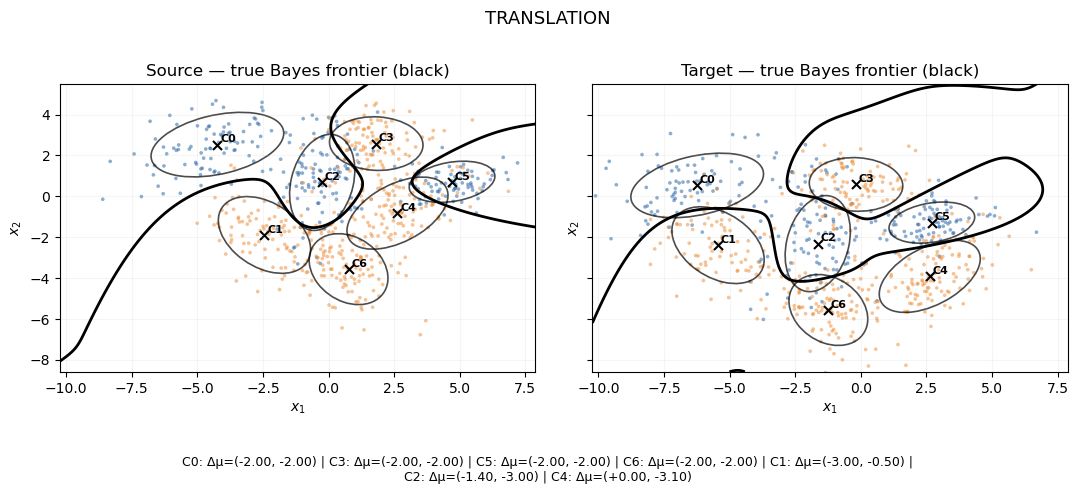

Held-out baseline scores:


,method,source_accuracy,target_accuracy
0,Source-only,0.849,0.619
1,Target-only,0.537,0.655
2,Pooled (no adaptation),0.842,0.629


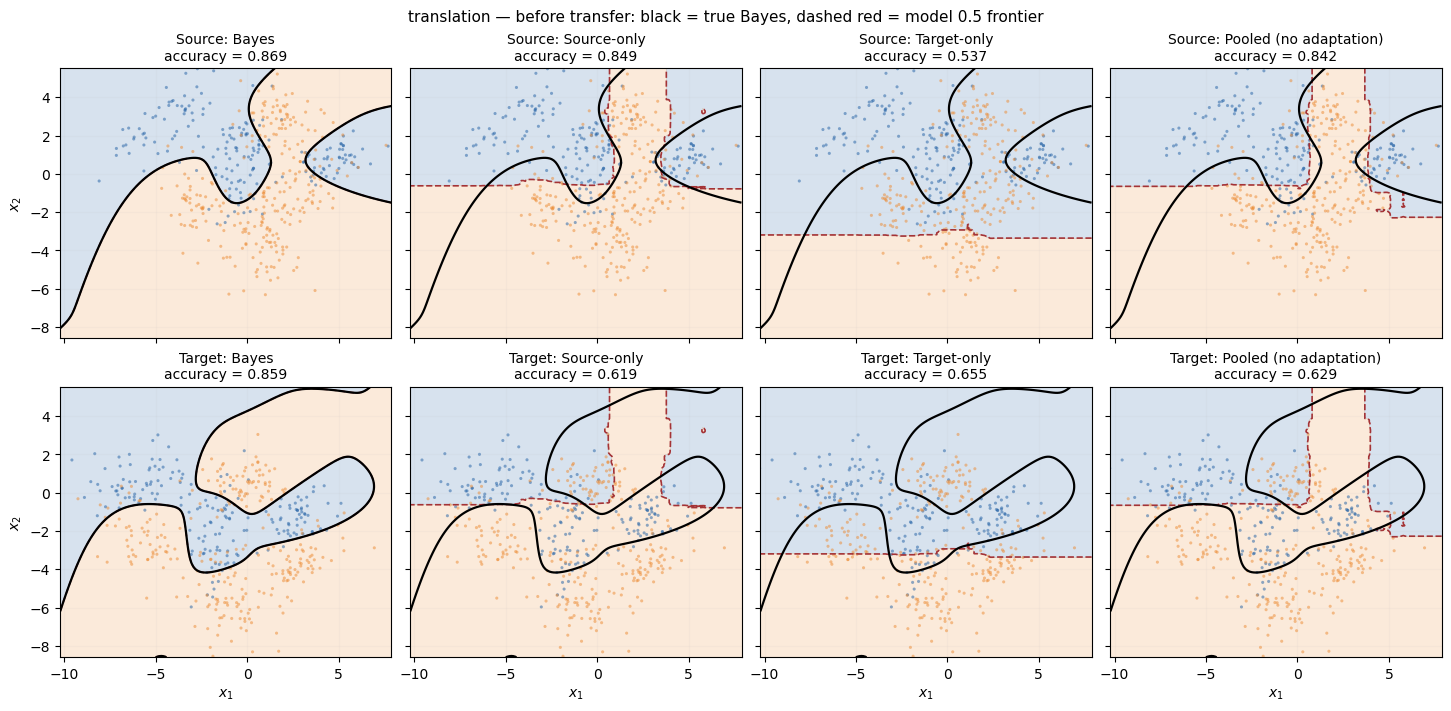

In [32]:
# Independent source and target draws from the saved probability laws.
Xs_train, ys_train, _, cs_train = sample_from_distribution(source_spec, SOURCE_N, seed=SEED)
Xs_test, ys_test, _, cs_test = sample_from_distribution(source_spec, SOURCE_TEST_N, seed=SEED + 1)
Xt_train, yt_train, _, ct_train, target_spec, notes = sample_target(
    source_spec, SCENARIO, TARGET_N, seed=SEED + 2,
    strength=STRENGTH, params=SCENARIO_PARAMS
)
Xt_test, yt_test, _, ct_test, _, _ = sample_target(
    source_spec, SCENARIO, TARGET_TEST_N, seed=SEED + 3,
    strength=STRENGTH, params=SCENARIO_PARAMS
)

print('Exact target edits:')
for note in notes:
    print('  •', note)
plot_domains(Xs_test, ys_test, Xt_test, yt_test, source_spec, target_spec,
             SCENARIO, notes, save=RESULTS / f'{SCENARIO}_01_domains.png')

# Three independent fitted controls; the pooled model is a useful diagnostic.
source_model = clone(base_estimator)
source_model.fit(Xs_train, ys_train)

target_model = clone(base_estimator)
target_model.fit(Xt_train, yt_train)                  # target LABELS are used

pooled_model = clone(base_estimator)
pooled_model.fit(np.vstack([Xs_train, Xt_train]), np.r_[ys_train, yt_train])

baseline_models = {'Source-only': source_model,
                   'Target-only': target_model,
                   'Pooled (no adaptation)': pooled_model}

baseline_scores = []
for label, predictor in baseline_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    baseline_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))
print('Held-out baseline scores:')
display(pd.DataFrame(baseline_scores).round(3))

# Bayes frontier + baseline decision regions, on SOURCE and TARGET.
plot_predictions(baseline_models, Xs_test, ys_test, Xt_test, yt_test,
                 source_spec, target_spec, SCENARIO + ' — before transfer',
                 save=RESULTS / f'{SCENARIO}_02_baselines.png')

**C. Adapt the pretrained source model using labeled target training data; evaluate on untouched test samples.** These are the actual ADAPT calls, not helper wrappers.

,scenario,method,source_accuracy,target_accuracy
0,translation,Source-only,0.849,0.619
1,translation,Target-only,0.537,0.655
2,translation,Pooled (no adaptation),0.842,0.629
3,translation,RELABEL,0.674,0.741
4,translation,SER,0.554,0.762
5,translation,STRUT,0.547,0.737
6,translation,Forest selector,0.630,0.727


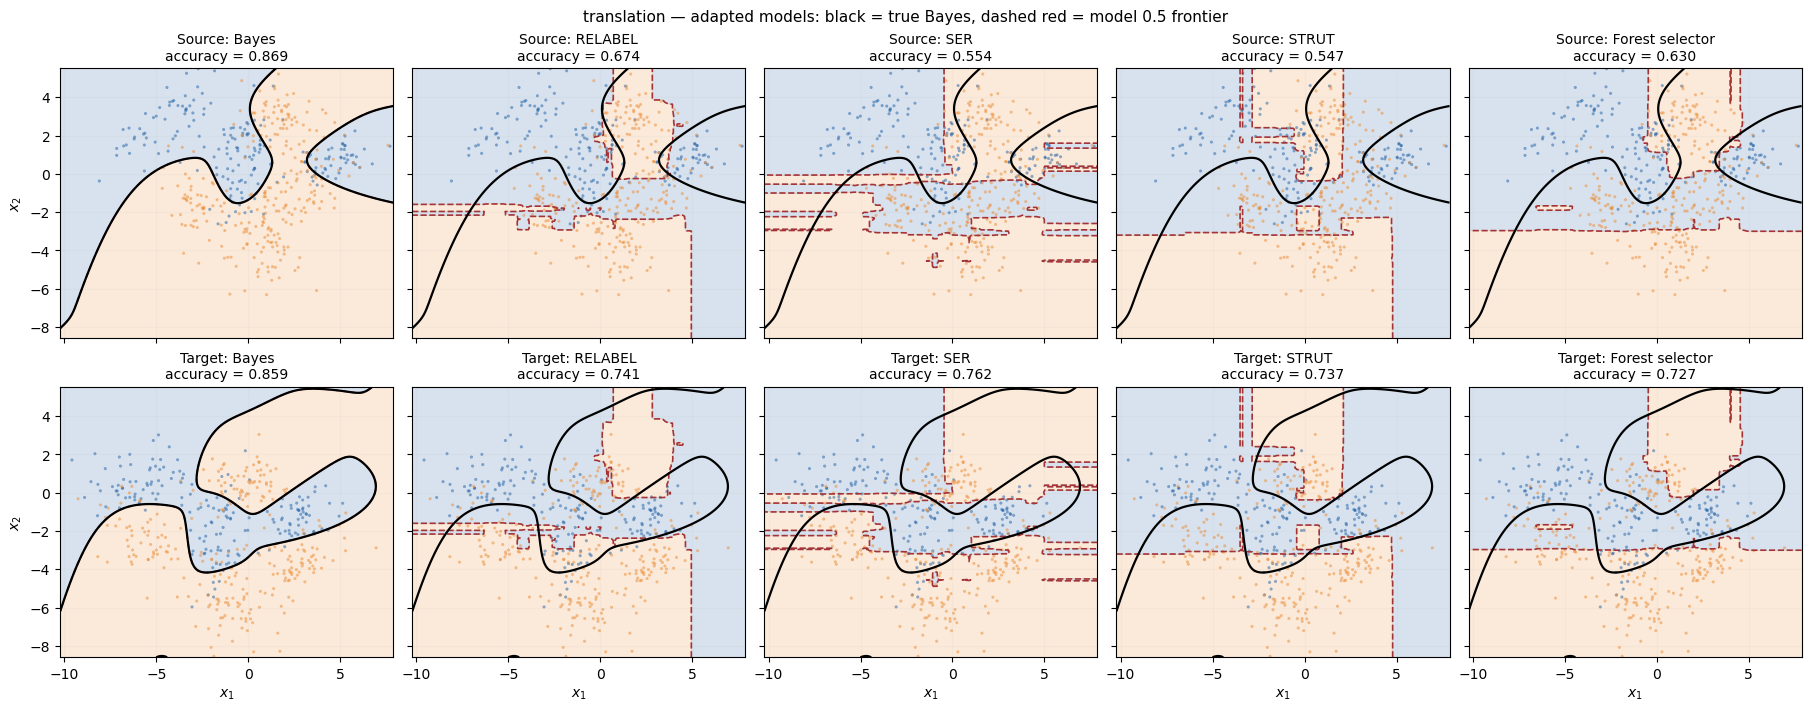

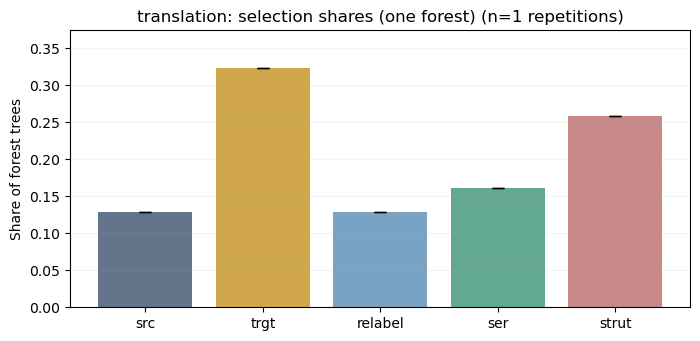

src=keep source; trgt=learn target; relab=change leaves; ser=expand/reduce; strut=adjust split conditions.


In [35]:
transferred_models = {}
selection_indices = None

if HAVE_ADAPT:
    for algorithm in ('relabel', 'ser', 'strut'):
        try:
            TransferClass = (TransferTreeClassifier if MODEL_KIND == 'tree'
                             else TransferForestClassifier)
            adapted = TransferClass(
                estimator=copy.deepcopy(source_model),
                algo=algorithm, copy=True, verbose=0, random_state=RANDOM_SEED
            )
            fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )
            
            adapted.fit(Xt_train, yt_train, **fit_params) 
            transferred_models[algorithm.upper()] = adapted.estimator_
        except Exception as exc:
            print(f'{algorithm.upper()} failed: {type(exc).__name__}: {exc}')

    if MODEL_KIND == 'forest':
        try:
            
            selector = TransferForestSelector(
                estimator=copy.deepcopy(source_model),
                algorithms=ALGORITHMS, copy=True, verbose=0,
                random_state=RANDOM_SEED,
                list_alg_args = LIST_ALG_ARGS
            )
            selector.model_selection(Xt_train, yt_train,
                                     score_type='auc', oob_=True)
            transferred_models['Forest selector'] = selector.STRF_model.estimator_
            selection_indices = np.asarray(selector.STRF_indexes, dtype=int)
        except Exception as exc:
            print(f'Forest selector failed: {type(exc).__name__}: {exc}')
else:
    print('ADAPT missing: relabel/SER/STRUT/selector NOT evaluated.')

transfer_scores = []
for label, predictor in transferred_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    transfer_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))

all_case_scores = pd.DataFrame(baseline_scores + transfer_scores)
all_case_scores.insert(0, 'scenario', SCENARIO)
SCENARIO_SCORES.extend(all_case_scores.to_dict('records'))
display(all_case_scores.round(3))
all_case_scores.to_csv(RESULTS / f'{SCENARIO}_scores.csv', index=False)

if transferred_models:
    plot_predictions(transferred_models, Xs_test, ys_test, Xt_test, yt_test,
                     source_spec, target_spec, SCENARIO + ' — adapted models',
                     save=RESULTS / f'{SCENARIO}_03_transferred.png')

    # Change to plot the training data :
    #plot_predictions(transferred_models, Xs_test, ys_test, Xt_train, yt_train,
    #                 source_spec, target_spec, SCENARIO + ' — adapted models',
    #                 save=RESULTS / f'{SCENARIO}_03_transferred.png')

if MODEL_KIND == 'tree' and PLOT_TREE_DIAGRAMS:
    for algorithm, predictor in transferred_models.items():
        if hasattr(predictor, 'tree_'):
            changes = plot_tree_diff(source_model, predictor,
                title=f'{SCENARIO}: source → {algorithm}',
                max_depth=TREE_PLOT_DEPTH,
                save=RESULTS / f'{SCENARIO}_{algorithm.lower()}_tree.png')
            print(f'{algorithm}: {len(changes)} matched paths changed; ' +
                  'solid red=structure, dashed red=threshold, amber=leaf class')

if MODEL_KIND == 'forest' and selection_indices is not None:
    plot_selection_frequencies([selection_indices], ALGORITHMS,
        f'{SCENARIO}: selection shares (one forest)',
        save=RESULTS / f'{SCENARIO}_selector.png')
    print('src=keep source; trgt=learn target; relab=change leaves; '
          'ser=expand/reduce; strut=adjust split conditions.')

**D. Repeat the experiment on fresh samples from the same distributions.** Change `N_REPETITIONS` in this scenario’s settings. Each repetition redraws source/target training **and** held-out test data, fits all baseline and ADAPT models from scratch, and computes paired target scores. The single-run prediction figures above remain as an illustration; the table below is the average over repetitions. Forest method-selection bars are also averaged over repetitions.

translation: 10 newly sampled training/test realizations
Held-out accuracy: mean ± SD across independent draws


,method,n_runs,source_mean,source_std,target_mean,target_std
0,Forest selector,10,0.592,0.081,0.754,0.047
1,Pooled (no adaptation),10,0.839,0.006,0.621,0.010
2,RELABEL,10,0.593,0.059,0.702,0.034
3,SER,10,0.516,0.051,0.760,0.038
4,STRUT,10,0.565,0.034,0.737,0.045
5,Source-only,10,0.837,0.007,0.617,0.011
6,Target-only,10,0.574,0.044,0.712,0.043


Paired transfer improvements; > 0 means better than BOTH baselines in that repetition


,method,mean_gain_vs_best_baseline,sd_gain,fraction_positive,mean_gain_vs_pooling,n_paired
0,Forest selector,0.042,0.045,0.9,0.132,10
1,RELABEL,-0.010,0.029,0.3,0.080,10
2,SER,0.048,0.062,0.7,0.139,10
3,STRUT,0.024,0.052,0.8,0.115,10


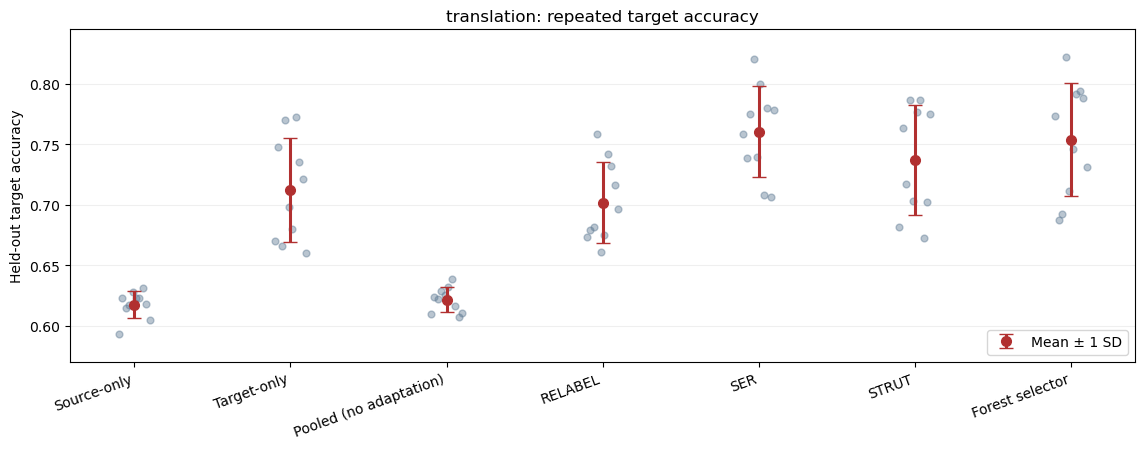

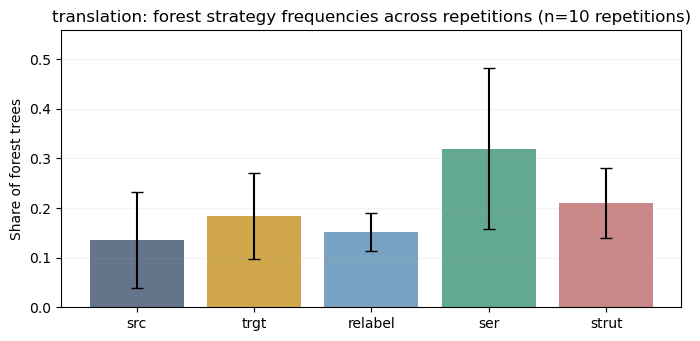

In [38]:
# Restore this section's recorded settings, even if other sections ran afterward.
SCENARIO = 'translation'
_rep_cfg = SCENARIO_CONFIGS[SCENARIO]
SCENARIO_PARAMS = copy.deepcopy(_rep_cfg['params'])
STRENGTH = _rep_cfg['strength']
SOURCE_N, TARGET_N = _rep_cfg['source_n'], _rep_cfg['target_n']
SOURCE_TEST_N, TARGET_TEST_N = _rep_cfg['source_test_n'], _rep_cfg['target_test_n']
SEED = _rep_cfg['seed']
RUN_REPETITIONS = _rep_cfg['run_repetitions']
N_REPETITIONS = _rep_cfg['n_repetitions']

# Independent draws from the SAME fixed source and target distributions.
# This is separate from the illustrative single-run plots above.
# Every repetition re-draws BOTH labeled training sets and BOTH held-out test sets.
repeated_rows = []
repeated_selections = []
failed_adapt = []


if RUN_REPETITIONS:
    for rep in range(N_REPETITIONS):
        rep_seed = SEED + 100_000 + 10 * rep

        Xs_rep, ys_rep, _, _ = sample_from_distribution(
            source_spec, SOURCE_N, seed=rep_seed)
        Xs_eval, ys_eval, _, _ = sample_from_distribution(
            source_spec, SOURCE_TEST_N, seed=rep_seed + 1)
        Xt_rep, yt_rep, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_N, seed=rep_seed + 2,
            strength=STRENGTH, params=SCENARIO_PARAMS)
        Xt_eval, yt_eval, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_TEST_N, seed=rep_seed + 3,
            strength=STRENGTH, params=SCENARIO_PARAMS)

        # Baseline fits — exactly the SAME datasets and test samples per repetition.
        src_rep_model = clone(base_estimator)
        src_rep_model.fit(Xs_rep, ys_rep)
        tgt_rep_model = clone(base_estimator)
        tgt_rep_model.fit(Xt_rep, yt_rep)
        pooled_rep_model = clone(base_estimator)
        pooled_rep_model.fit(np.vstack((Xs_rep, Xt_rep)), np.r_[ys_rep, yt_rep])
        rep_models = {
            'Source-only': src_rep_model,
            'Target-only': tgt_rep_model,
            'Pooled (no adaptation)': pooled_rep_model,
        }

        # Supervised ADAPT methods — use the FITTED SOURCE model and labeled TARGET data.
        if HAVE_ADAPT:
            for algo in ('relabel', 'ser', 'strut'):
                try:
                    cls = TransferTreeClassifier if MODEL_KIND == 'tree' else TransferForestClassifier
                    adapted = cls(estimator=copy.deepcopy(src_rep_model), algo=algo,
                                  copy=True, verbose=0, random_state=RANDOM_SEED)
                    
                    fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )            
                    adapted.fit(Xt_rep, yt_rep, **fit_params) 
                    
                    rep_models[algo.upper()] = adapted.estimator_
                except Exception as exc:
                    failed_adapt.append((rep, algo, type(exc).__name__, str(exc)[:120]))

            if MODEL_KIND == 'forest':
                try:
                    selector = TransferForestSelector(
                        estimator=copy.deepcopy(src_rep_model), algorithms=ALGORITHMS,
                        copy=True, verbose=0, random_state=RANDOM_SEED,list_alg_args=LIST_ALG_ARGS)
                    selector.model_selection(Xt_rep, yt_rep, score_type='auc', oob_=True)
                    rep_models['Forest selector'] = selector.STRF_model.estimator_
                    repeated_selections.append(np.asarray(selector.STRF_indexes, dtype=int))
                except Exception as exc:
                    failed_adapt.append((rep, 'selector', type(exc).__name__, str(exc)[:120]))

        # Paired evaluation: all methods share each repetition's held-out samples.
        for name, fitted_model in rep_models.items():
            repeated_rows.append({
                'scenario': SCENARIO, 'rep': rep, 'seed': rep_seed, 'method': name,
                'source_accuracy': accuracy_score(ys_eval, fitted_model.predict(Xs_eval)),
                'target_accuracy': accuracy_score(yt_eval, fitted_model.predict(Xt_eval)),
            })

    repeated_df = pd.DataFrame(repeated_rows)
    repeated_df.to_csv(RESULTS / f'{SCENARIO}_repeated_scores.csv', index=False)

    # Mean ± SD across random draws; these are NOT scores from the example plots.
    repeated_summary = (repeated_df.groupby('method')
        .agg(n_runs=('target_accuracy', 'count'),
             source_mean=('source_accuracy', 'mean'),
             source_std=('source_accuracy', 'std'),
             target_mean=('target_accuracy', 'mean'),
             target_std=('target_accuracy', 'std'))
        .reset_index())

    # Per-repetition gain over the better of source-only and target-only.
    paired = repeated_df.pivot(index='rep', columns='method', values='target_accuracy')
    best_base = paired[['Source-only', 'Target-only']].max(axis=1)
    gain_rows = []
    for name in paired.columns:
        if name in ('Source-only', 'Target-only', 'Pooled (no adaptation)'):
            continue
        gain = (paired[name] - best_base).dropna()
        pool_gain = (paired[name] - paired['Pooled (no adaptation)']).dropna()
        gain_rows.append({
            'method': name, 'mean_gain_vs_best_baseline': gain.mean(),
            'sd_gain': gain.std(), 'fraction_positive': (gain > 0).mean(),
            'mean_gain_vs_pooling': pool_gain.mean(), 'n_paired': len(gain),
        })
    gains_df = pd.DataFrame(gain_rows)

    print(f'{SCENARIO}: {N_REPETITIONS} newly sampled training/test realizations')
    print('Held-out accuracy: mean ± SD across independent draws')
    display(repeated_summary.round(3))
    if not gains_df.empty:
        print('Paired transfer improvements; > 0 means better than BOTH baselines in that repetition')
        display(gains_df.round(3))
        gains_df.to_csv(RESULTS / f'{SCENARIO}_paired_gains.csv', index=False)
    # Replace this section's previous summary when rerunning just this block.
    SCENARIO_REPEAT_SUMMARIES[:] = [r for r in SCENARIO_REPEAT_SUMMARIES
                                    if r['scenario'] != SCENARIO]
    SCENARIO_REPEAT_SUMMARIES.extend(
        [dict(scenario=SCENARIO, **row) for row in repeated_summary.to_dict('records')])

    plot_repeated_accuracy(repeated_df, title=f'{SCENARIO}: repeated target accuracy',
        save=RESULTS / f'{SCENARIO}_04_repeated_accuracy.png')

    if MODEL_KIND == 'forest' and repeated_selections:
        plot_selection_frequencies(repeated_selections, ALGORITHMS,
            f'{SCENARIO}: forest strategy frequencies across repetitions',
            save=RESULTS / f'{SCENARIO}_05_repeated_selector.png')

    if failed_adapt:
        print(f'ADAPT fitting failures: {len(failed_adapt)}. First examples:')
        display(pd.DataFrame(failed_adapt, columns=['rep','algo','error_type','message']).head(5))
else:
    print('Repetitions disabled for this scenario. Set RUN_REPETITIONS=True above.')


## 4. Remove one cluster and add another

Component addition/removal.

**A. Edit the settings below and rerun this section only.**

In [41]:
SCENARIO = 'add_remove'

SCENARIO_PARAMS = {
    'remove': [1],
    'add': [{
        'mean': [-1, 3.50],
        'cov_params': [1, 0.5, 20.0],  # principal std1, std2, degrees
        'weight': 0.15,                    # raw weight, then renormalized
        'label': 1,
        'regression_base_level': 0.40,
        'regression_local_amplitude': 0.15,
        'regression_gradient_angle_deg': 22.0,
    },
    {
        'mean': [-3, -2],
        'cov_params': [1, 0.5, -45.0],  # principal std1, std2, degrees
        'weight': 0.1,                    # raw weight, then renormalized
        'label': 0,
        'regression_base_level': 0.5,
        'regression_local_amplitude': 0.1,
        'regression_gradient_angle_deg': 0,
    },
    {
        'mean': [5, -4],
        'cov_params': [1, 0.5, -45.0],  # principal std1, std2, degrees
        'weight': 0.1,                    # raw weight, then renormalized
        'label': 0,
        'regression_base_level': 0.5,
        'regression_local_amplitude': 0.1,
        'regression_gradient_angle_deg': 0,
    }

    ],
}
STRENGTH = 1.0  
SOURCE_N = 500
TARGET_N = 50
SOURCE_TEST_N = 3000
TARGET_TEST_N = 3000

RUN_REPETITIONS = True
N_REPETITIONS = 10     # Increase to 20–30 for more stable uncertainty estimates
SEED = RANDOM_SEED + 4_000

SCENARIO_CONFIGS[SCENARIO] = dict(
    params=copy.deepcopy(SCENARIO_PARAMS), strength=STRENGTH,
    source_n=SOURCE_N, target_n=TARGET_N,
    source_test_n=SOURCE_TEST_N, target_test_n=TARGET_TEST_N, seed=SEED,
    n_repetitions=N_REPETITIONS, run_repetitions=RUN_REPETITIONS
)
print('Selected configuration:', SCENARIO_CONFIGS[SCENARIO])

Selected configuration: {'params': {'remove': [1], 'add': [{'mean': [-1, 3.5], 'cov_params': [1, 0.5, 20.0], 'weight': 0.15, 'label': 1, 'regression_base_level': 0.4, 'regression_local_amplitude': 0.15, 'regression_gradient_angle_deg': 22.0}, {'mean': [-3, -2], 'cov_params': [1, 0.5, -45.0], 'weight': 0.1, 'label': 0, 'regression_base_level': 0.5, 'regression_local_amplitude': 0.1, 'regression_gradient_angle_deg': 0}, {'mean': [5, -4], 'cov_params': [1, 0.5, -45.0], 'weight': 0.1, 'label': 0, 'regression_base_level': 0.5, 'regression_local_amplitude': 0.1, 'regression_gradient_angle_deg': 0}]}, 'strength': 1.0, 'source_n': 500, 'target_n': 50, 'source_test_n': 3000, 'target_test_n': 3000, 'seed': 20265102, 'n_repetitions': 10, 'run_repetitions': True}


**B. Generate data, visualize both domains, train and evaluate the source-only and target-only baselines.** No transfer occurs in this cell.

Exact target edits:
  • Remove C1 (class 1)
  • Add C7: class=1, μ=[-1, 3.5], axes/angle=[1, 0.5, 20.0], raw weight=0.15
  • Add C8: class=0, μ=[-3, -2], axes/angle=[1, 0.5, -45.0], raw weight=0.1
  • Add C9: class=0, μ=[5, -4], axes/angle=[1, 0.5, -45.0], raw weight=0.1


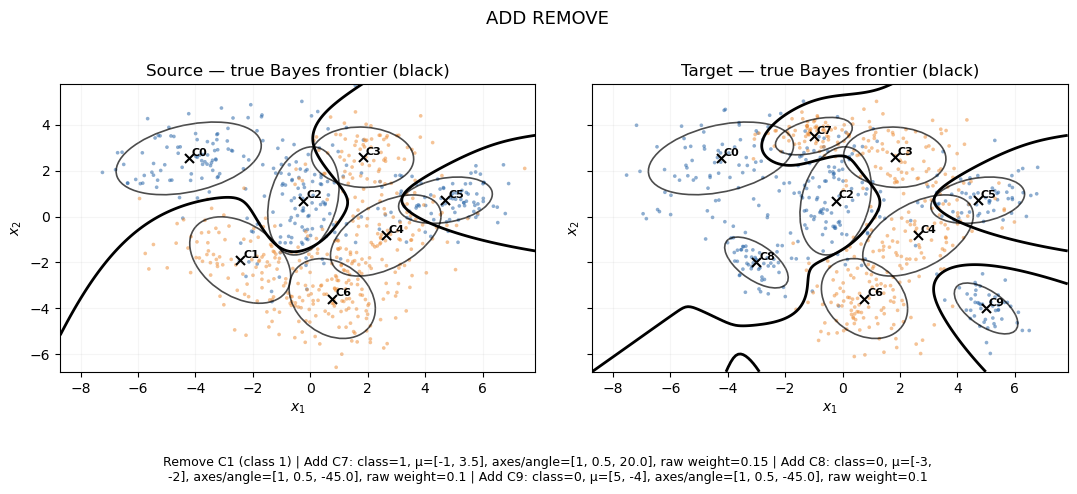

Held-out baseline scores:


,method,source_accuracy,target_accuracy
0,Source-only,0.832,0.620
1,Target-only,0.666,0.790
2,Pooled (no adaptation),0.827,0.623


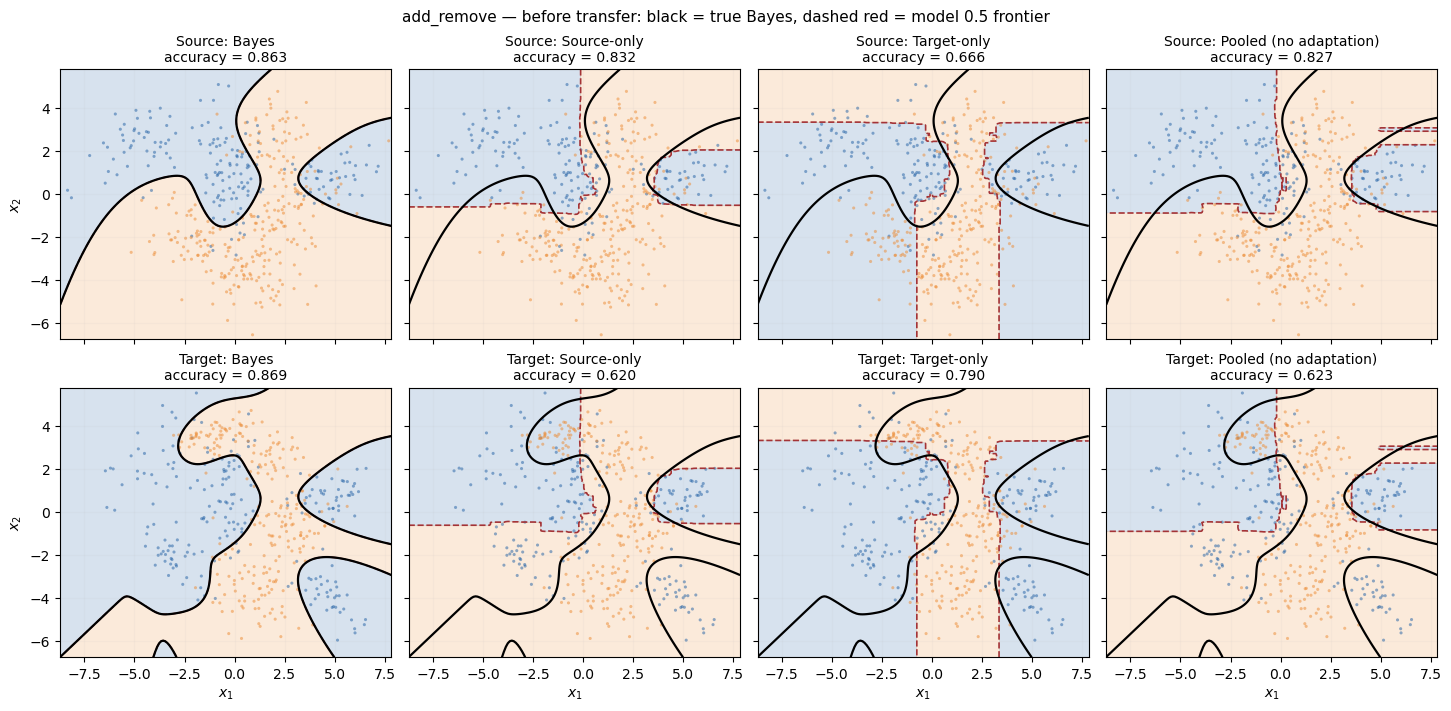

In [44]:
# Independent source and target draws from the saved probability laws.
Xs_train, ys_train, _, cs_train = sample_from_distribution(source_spec, SOURCE_N, seed=SEED)
Xs_test, ys_test, _, cs_test = sample_from_distribution(source_spec, SOURCE_TEST_N, seed=SEED + 1)
Xt_train, yt_train, _, ct_train, target_spec, notes = sample_target(
    source_spec, SCENARIO, TARGET_N, seed=SEED + 2,
    strength=STRENGTH, params=SCENARIO_PARAMS
)
Xt_test, yt_test, _, ct_test, _, _ = sample_target(
    source_spec, SCENARIO, TARGET_TEST_N, seed=SEED + 3,
    strength=STRENGTH, params=SCENARIO_PARAMS
)

print('Exact target edits:')
for note in notes:
    print('  •', note)
plot_domains(Xs_test, ys_test, Xt_test, yt_test, source_spec, target_spec,
             SCENARIO, notes, save=RESULTS / f'{SCENARIO}_01_domains.png')

# Three independent fitted controls; the pooled model is a useful diagnostic.
source_model = clone(base_estimator)
source_model.fit(Xs_train, ys_train)

target_model = clone(base_estimator)
target_model.fit(Xt_train, yt_train)                  # target LABELS are used

pooled_model = clone(base_estimator)
pooled_model.fit(np.vstack([Xs_train, Xt_train]), np.r_[ys_train, yt_train])

baseline_models = {'Source-only': source_model,
                   'Target-only': target_model,
                   'Pooled (no adaptation)': pooled_model}

baseline_scores = []
for label, predictor in baseline_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    baseline_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))
print('Held-out baseline scores:')
display(pd.DataFrame(baseline_scores).round(3))

# Bayes frontier + baseline decision regions, on SOURCE and TARGET.
plot_predictions(baseline_models, Xs_test, ys_test, Xt_test, yt_test,
                 source_spec, target_spec, SCENARIO + ' — before transfer',
                 save=RESULTS / f'{SCENARIO}_02_baselines.png')

**C. Adapt the pretrained source model using labeled target training data; evaluate on untouched test samples.** These are the actual ADAPT calls, not helper wrappers.

,scenario,method,source_accuracy,target_accuracy
0,add_remove,Source-only,0.832,0.620
1,add_remove,Target-only,0.666,0.790
2,add_remove,Pooled (no adaptation),0.827,0.623
3,add_remove,RELABEL,0.697,0.797
4,add_remove,SER,0.637,0.784
5,add_remove,STRUT,0.659,0.796
6,add_remove,Forest selector,0.694,0.828


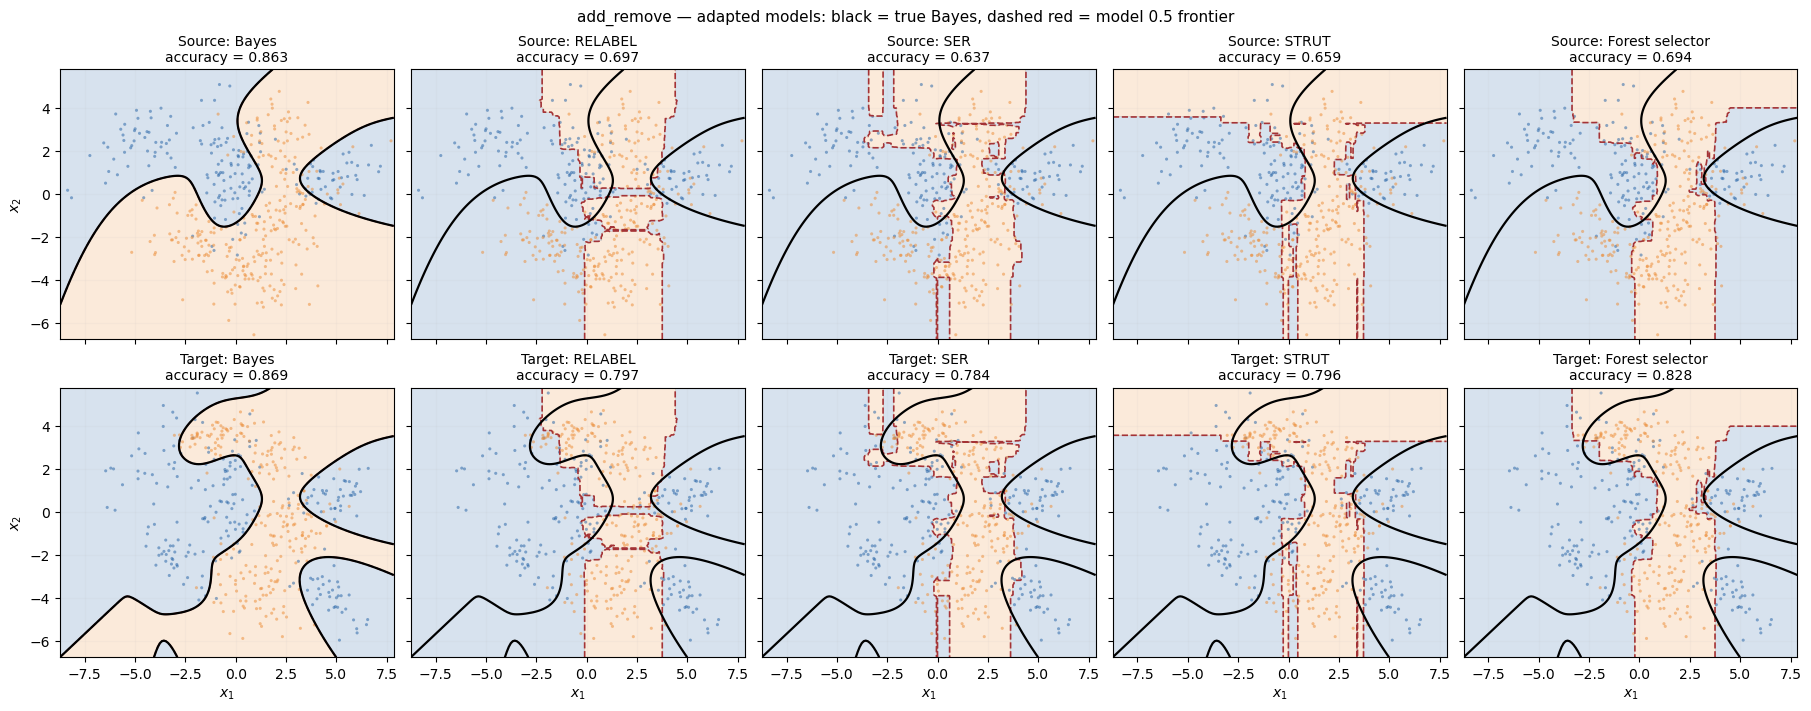

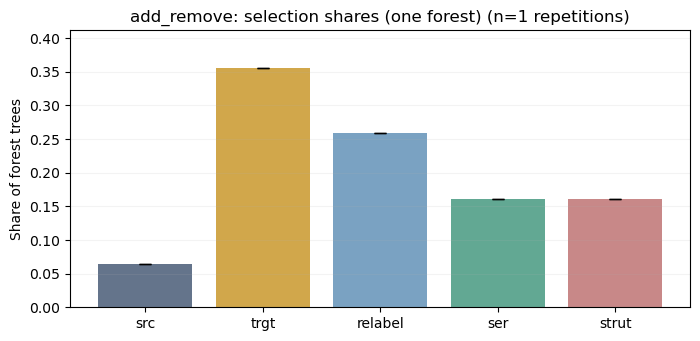

src=keep source; trgt=learn target; relab=change leaves; ser=expand/reduce; strut=adjust split conditions.


In [47]:
transferred_models = {}
selection_indices = None

if HAVE_ADAPT:
    for algorithm in ('relabel', 'ser', 'strut'):
        try:
            TransferClass = (TransferTreeClassifier if MODEL_KIND == 'tree'
                             else TransferForestClassifier)
            adapted = TransferClass(
                estimator=copy.deepcopy(source_model),
                algo=algorithm, copy=True, verbose=0, random_state=RANDOM_SEED
            )
            fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )
            
            adapted.fit(Xt_train, yt_train, **fit_params) 
            transferred_models[algorithm.upper()] = adapted.estimator_
        except Exception as exc:
            print(f'{algorithm.upper()} failed: {type(exc).__name__}: {exc}')

    if MODEL_KIND == 'forest':
        try:
            selector = TransferForestSelector(
                estimator=copy.deepcopy(source_model),
                algorithms=ALGORITHMS, copy=True, verbose=0,
                random_state=RANDOM_SEED
            )
            selector.model_selection(Xt_train, yt_train,
                                     score_type='auc', oob_=True)
            transferred_models['Forest selector'] = selector.STRF_model.estimator_
            selection_indices = np.asarray(selector.STRF_indexes, dtype=int)
        except Exception as exc:
            print(f'Forest selector failed: {type(exc).__name__}: {exc}')
else:
    print('ADAPT missing: relabel/SER/STRUT/selector NOT evaluated.')

transfer_scores = []
for label, predictor in transferred_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    transfer_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))

all_case_scores = pd.DataFrame(baseline_scores + transfer_scores)
all_case_scores.insert(0, 'scenario', SCENARIO)
SCENARIO_SCORES.extend(all_case_scores.to_dict('records'))
display(all_case_scores.round(3))
all_case_scores.to_csv(RESULTS / f'{SCENARIO}_scores.csv', index=False)

if transferred_models:
    plot_predictions(transferred_models, Xs_test, ys_test, Xt_test, yt_test,
                     source_spec, target_spec, SCENARIO + ' — adapted models',
                     save=RESULTS / f'{SCENARIO}_03_transferred.png')

    # Change to plot the training data :
    #plot_predictions(transferred_models, Xs_test, ys_test, Xt_train, yt_train,
    #                 source_spec, target_spec, SCENARIO + ' — adapted models',
    #                 save=RESULTS / f'{SCENARIO}_03_transferred.png')

if MODEL_KIND == 'tree' and PLOT_TREE_DIAGRAMS:
    for algorithm, predictor in transferred_models.items():
        if hasattr(predictor, 'tree_'):
            changes = plot_tree_diff(source_model, predictor,
                title=f'{SCENARIO}: source → {algorithm}',
                max_depth=TREE_PLOT_DEPTH,
                save=RESULTS / f'{SCENARIO}_{algorithm.lower()}_tree.png')
            print(f'{algorithm}: {len(changes)} matched paths changed; ' +
                  'solid red=structure, dashed red=threshold, amber=leaf class')

if MODEL_KIND == 'forest' and selection_indices is not None:
    plot_selection_frequencies([selection_indices], ALGORITHMS,
        f'{SCENARIO}: selection shares (one forest)',
        save=RESULTS / f'{SCENARIO}_selector.png')
    print('src=keep source; trgt=learn target; relab=change leaves; '
          'ser=expand/reduce; strut=adjust split conditions.')

**D. Repeat the experiment on fresh samples from the same distributions.** Change `N_REPETITIONS` in this scenario’s settings. Each repetition redraws source/target training **and** held-out test data, fits all baseline and ADAPT models from scratch, and computes paired target scores. The single-run prediction figures above remain as an illustration; the table below is the average over repetitions. Forest method-selection bars are also averaged over repetitions.

add_remove: 10 newly sampled training/test realizations
Held-out accuracy: mean ± SD across independent draws


,method,n_runs,source_mean,source_std,target_mean,target_std
0,Forest selector,10,0.728,0.050,0.749,0.076
1,Pooled (no adaptation),10,0.833,0.014,0.637,0.036
2,RELABEL,10,0.704,0.045,0.763,0.058
3,SER,10,0.687,0.029,0.776,0.041
4,STRUT,10,0.691,0.042,0.764,0.047
5,Source-only,10,0.835,0.011,0.604,0.010
6,Target-only,10,0.672,0.056,0.722,0.068


Paired transfer improvements; > 0 means better than BOTH baselines in that repetition


,method,mean_gain_vs_best_baseline,sd_gain,fraction_positive,mean_gain_vs_pooling,n_paired
0,Forest selector,0.027,0.041,0.8,0.112,10
1,RELABEL,0.041,0.047,0.8,0.126,10
2,SER,0.055,0.059,0.9,0.139,10
3,STRUT,0.042,0.048,0.9,0.127,10


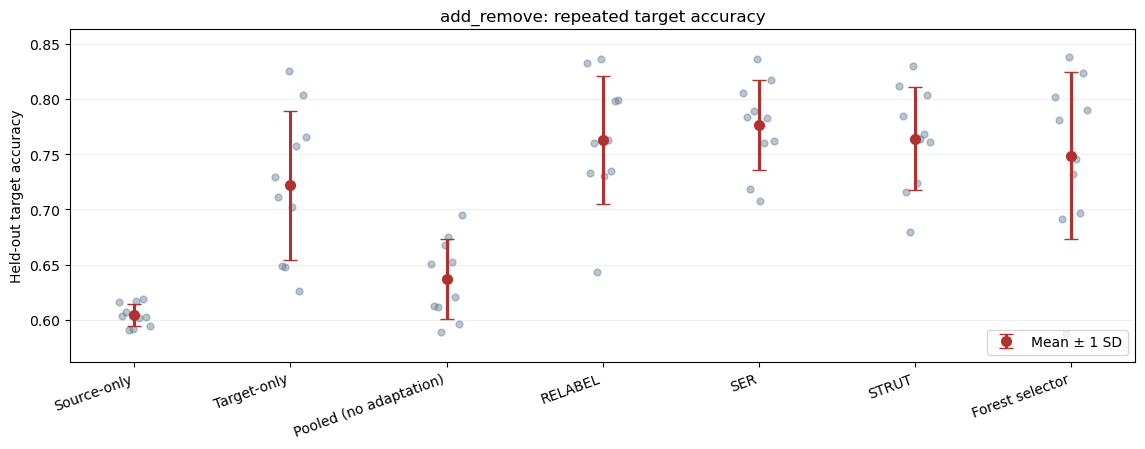

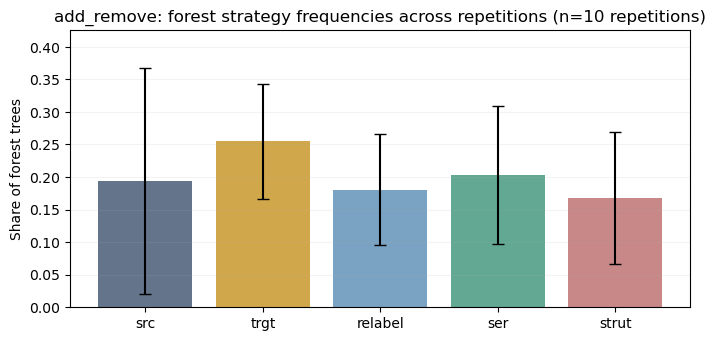

In [50]:
# Restore this section's recorded settings, even if other sections ran afterward.
SCENARIO = 'add_remove'
_rep_cfg = SCENARIO_CONFIGS[SCENARIO]
SCENARIO_PARAMS = copy.deepcopy(_rep_cfg['params'])
STRENGTH = _rep_cfg['strength']
SOURCE_N, TARGET_N = _rep_cfg['source_n'], _rep_cfg['target_n']
SOURCE_TEST_N, TARGET_TEST_N = _rep_cfg['source_test_n'], _rep_cfg['target_test_n']
SEED = _rep_cfg['seed']
RUN_REPETITIONS = _rep_cfg['run_repetitions']
N_REPETITIONS = _rep_cfg['n_repetitions']

# Independent draws from the SAME fixed source and target distributions.
# This is separate from the illustrative single-run plots above.
# Every repetition re-draws BOTH labeled training sets and BOTH held-out test sets.
repeated_rows = []
repeated_selections = []
failed_adapt = []

if RUN_REPETITIONS:
    for rep in range(N_REPETITIONS):
        rep_seed = SEED + 100_000 + 10 * rep

        Xs_rep, ys_rep, _, _ = sample_from_distribution(
            source_spec, SOURCE_N, seed=rep_seed)
        Xs_eval, ys_eval, _, _ = sample_from_distribution(
            source_spec, SOURCE_TEST_N, seed=rep_seed + 1)
        Xt_rep, yt_rep, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_N, seed=rep_seed + 2,
            strength=STRENGTH, params=SCENARIO_PARAMS)
        Xt_eval, yt_eval, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_TEST_N, seed=rep_seed + 3,
            strength=STRENGTH, params=SCENARIO_PARAMS)

        # Baseline fits — exactly the SAME datasets and test samples per repetition.
        src_rep_model = clone(base_estimator)
        src_rep_model.fit(Xs_rep, ys_rep)
        tgt_rep_model = clone(base_estimator)
        tgt_rep_model.fit(Xt_rep, yt_rep)
        pooled_rep_model = clone(base_estimator)
        pooled_rep_model.fit(np.vstack((Xs_rep, Xt_rep)), np.r_[ys_rep, yt_rep])
        rep_models = {
            'Source-only': src_rep_model,
            'Target-only': tgt_rep_model,
            'Pooled (no adaptation)': pooled_rep_model,
        }

        # Supervised ADAPT methods — use the FITTED SOURCE model and labeled TARGET data.
        if HAVE_ADAPT:
            for algo in ('relabel', 'ser', 'strut'):
                try:
                    cls = TransferTreeClassifier if MODEL_KIND == 'tree' else TransferForestClassifier
                    adapted = cls(estimator=copy.deepcopy(src_rep_model), algo=algo,
                                  copy=True, verbose=0, random_state=RANDOM_SEED)
                    fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )            
                    adapted.fit(Xt_rep, yt_rep, **fit_params) 
                    rep_models[algo.upper()] = adapted.estimator_
                except Exception as exc:
                    failed_adapt.append((rep, algo, type(exc).__name__, str(exc)[:120]))

            if MODEL_KIND == 'forest':
                try:
                    selector = TransferForestSelector(
                        estimator=copy.deepcopy(src_rep_model), algorithms=ALGORITHMS,
                        copy=True, verbose=0, random_state=RANDOM_SEED,list_alg_args=LIST_ALG_ARGS)
                    selector.model_selection(Xt_rep, yt_rep, score_type='auc', oob_=True)
                    rep_models['Forest selector'] = selector.STRF_model.estimator_
                    repeated_selections.append(np.asarray(selector.STRF_indexes, dtype=int))
                except Exception as exc:
                    failed_adapt.append((rep, 'selector', type(exc).__name__, str(exc)[:120]))

        # Paired evaluation: all methods share each repetition's held-out samples.
        for name, fitted_model in rep_models.items():
            repeated_rows.append({
                'scenario': SCENARIO, 'rep': rep, 'seed': rep_seed, 'method': name,
                'source_accuracy': accuracy_score(ys_eval, fitted_model.predict(Xs_eval)),
                'target_accuracy': accuracy_score(yt_eval, fitted_model.predict(Xt_eval)),
            })

    repeated_df = pd.DataFrame(repeated_rows)
    repeated_df.to_csv(RESULTS / f'{SCENARIO}_repeated_scores.csv', index=False)

    # Mean ± SD across random draws; these are NOT scores from the example plots.
    repeated_summary = (repeated_df.groupby('method')
        .agg(n_runs=('target_accuracy', 'count'),
             source_mean=('source_accuracy', 'mean'),
             source_std=('source_accuracy', 'std'),
             target_mean=('target_accuracy', 'mean'),
             target_std=('target_accuracy', 'std'))
        .reset_index())

    # Per-repetition gain over the better of source-only and target-only.
    paired = repeated_df.pivot(index='rep', columns='method', values='target_accuracy')
    best_base = paired[['Source-only', 'Target-only']].max(axis=1)
    gain_rows = []
    for name in paired.columns:
        if name in ('Source-only', 'Target-only', 'Pooled (no adaptation)'):
            continue
        gain = (paired[name] - best_base).dropna()
        pool_gain = (paired[name] - paired['Pooled (no adaptation)']).dropna()
        gain_rows.append({
            'method': name, 'mean_gain_vs_best_baseline': gain.mean(),
            'sd_gain': gain.std(), 'fraction_positive': (gain > 0).mean(),
            'mean_gain_vs_pooling': pool_gain.mean(), 'n_paired': len(gain),
        })
    gains_df = pd.DataFrame(gain_rows)

    print(f'{SCENARIO}: {N_REPETITIONS} newly sampled training/test realizations')
    print('Held-out accuracy: mean ± SD across independent draws')
    display(repeated_summary.round(3))
    if not gains_df.empty:
        print('Paired transfer improvements; > 0 means better than BOTH baselines in that repetition')
        display(gains_df.round(3))
        gains_df.to_csv(RESULTS / f'{SCENARIO}_paired_gains.csv', index=False)
    # Replace this section's previous summary when rerunning just this block.
    SCENARIO_REPEAT_SUMMARIES[:] = [r for r in SCENARIO_REPEAT_SUMMARIES
                                    if r['scenario'] != SCENARIO]
    SCENARIO_REPEAT_SUMMARIES.extend(
        [dict(scenario=SCENARIO, **row) for row in repeated_summary.to_dict('records')])

    plot_repeated_accuracy(repeated_df, title=f'{SCENARIO}: repeated target accuracy',
        save=RESULTS / f'{SCENARIO}_04_repeated_accuracy.png')

    if MODEL_KIND == 'forest' and repeated_selections:
        plot_selection_frequencies(repeated_selections, ALGORITHMS,
            f'{SCENARIO}: forest strategy frequencies across repetitions',
            save=RESULTS / f'{SCENARIO}_05_repeated_selector.png')

    if failed_adapt:
        print(f'ADAPT fitting failures: {len(failed_adapt)}. First examples:')
        display(pd.DataFrame(failed_adapt, columns=['rep','algo','error_type','message']).head(5))
else:
    print('Repetitions disabled for this scenario. Set RUN_REPETITIONS=True above.')


## 5. Flip class labels of selected clusters

Change the label rule, not the feature geometry. The original random choice is frozen explicitly below so you can edit the cluster IDs.

**A. Edit the settings below and rerun this section only.**

In [52]:
SCENARIO = 'relabel'
SCENARIO_PARAMS = {
    'flip_clusters': [2, 3, 4, 5],  
}
STRENGTH = 1.0  
SOURCE_N = 500
TARGET_N = 50
SOURCE_TEST_N = 3000
TARGET_TEST_N = 3000

RUN_REPETITIONS = True
N_REPETITIONS = 10     # Increase to 20–30 for more stable uncertainty estimates
SEED = RANDOM_SEED + 5_000

SCENARIO_CONFIGS[SCENARIO] = dict(
    params=copy.deepcopy(SCENARIO_PARAMS), strength=STRENGTH,
    source_n=SOURCE_N, target_n=TARGET_N,
    source_test_n=SOURCE_TEST_N, target_test_n=TARGET_TEST_N, seed=SEED,
    n_repetitions=N_REPETITIONS, run_repetitions=RUN_REPETITIONS
)
print('Selected configuration:', SCENARIO_CONFIGS[SCENARIO])

Selected configuration: {'params': {'flip_clusters': [2, 3, 4, 5]}, 'strength': 1.0, 'source_n': 500, 'target_n': 50, 'source_test_n': 3000, 'target_test_n': 3000, 'seed': 20266102, 'n_repetitions': 10, 'run_repetitions': True}


**B. Generate data, visualize both domains, train and evaluate the source-only and target-only baselines.** No transfer occurs in this cell.

Exact target edits:
  • C2: class 0→1
  • C3: class 1→0
  • C4: class 1→0
  • C5: class 0→1


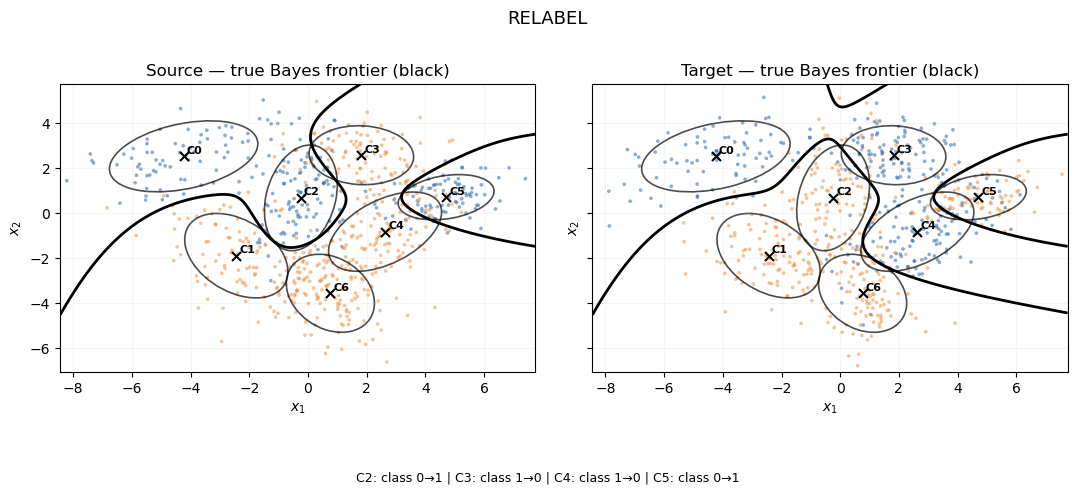

Held-out baseline scores:


,method,source_accuracy,target_accuracy
0,Source-only,0.837,0.563
1,Target-only,0.697,0.686
2,Pooled (no adaptation),0.817,0.577


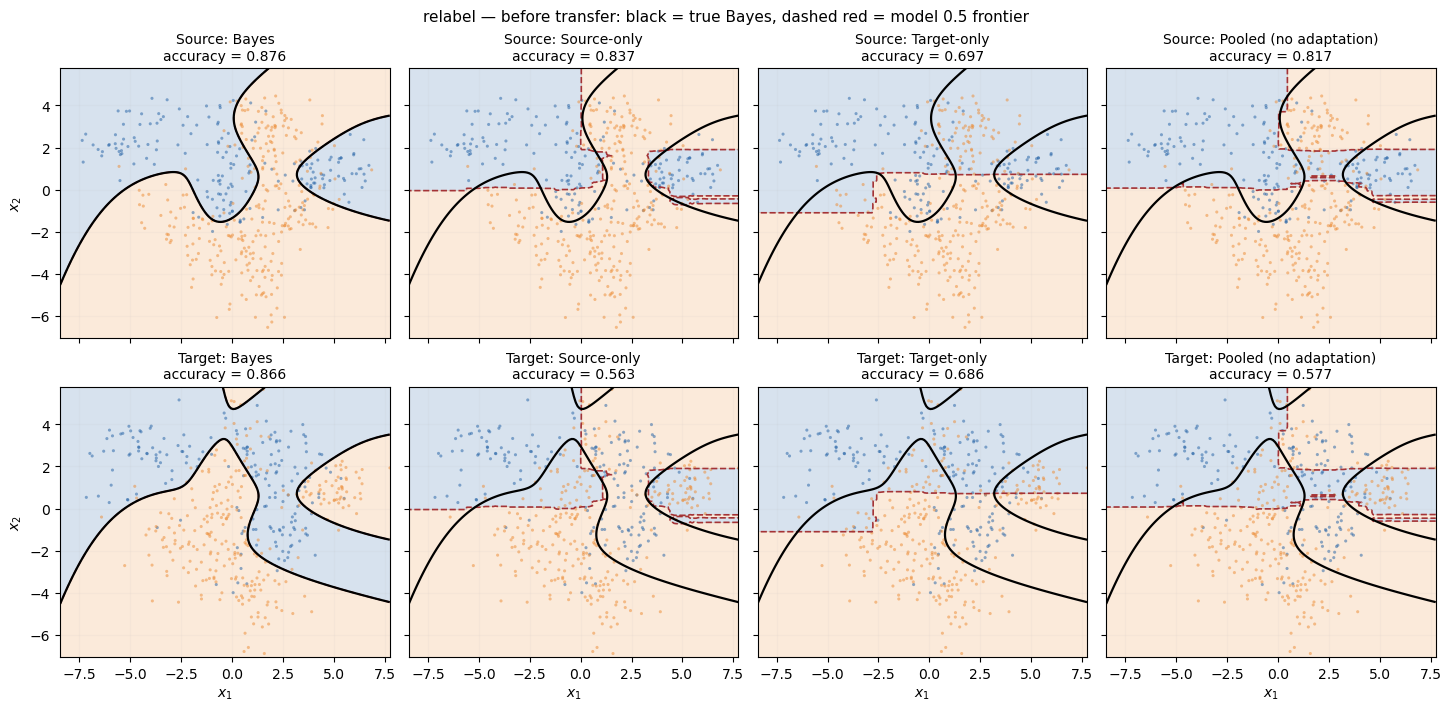

In [55]:
# Independent source and target draws from the saved probability laws.
Xs_train, ys_train, _, cs_train = sample_from_distribution(source_spec, SOURCE_N, seed=SEED)
Xs_test, ys_test, _, cs_test = sample_from_distribution(source_spec, SOURCE_TEST_N, seed=SEED + 1)
Xt_train, yt_train, _, ct_train, target_spec, notes = sample_target(
    source_spec, SCENARIO, TARGET_N, seed=SEED + 2,
    strength=STRENGTH, params=SCENARIO_PARAMS
)
Xt_test, yt_test, _, ct_test, _, _ = sample_target(
    source_spec, SCENARIO, TARGET_TEST_N, seed=SEED + 3,
    strength=STRENGTH, params=SCENARIO_PARAMS
)

print('Exact target edits:')
for note in notes:
    print('  •', note)
plot_domains(Xs_test, ys_test, Xt_test, yt_test, source_spec, target_spec,
             SCENARIO, notes, save=RESULTS / f'{SCENARIO}_01_domains.png')

# Three independent fitted controls; the pooled model is a useful diagnostic.
source_model = clone(base_estimator)
source_model.fit(Xs_train, ys_train)

target_model = clone(base_estimator)
target_model.fit(Xt_train, yt_train)                  # target LABELS are used

pooled_model = clone(base_estimator)
pooled_model.fit(np.vstack([Xs_train, Xt_train]), np.r_[ys_train, yt_train])

baseline_models = {'Source-only': source_model,
                   'Target-only': target_model,
                   'Pooled (no adaptation)': pooled_model}

baseline_scores = []
for label, predictor in baseline_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    baseline_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))
print('Held-out baseline scores:')
display(pd.DataFrame(baseline_scores).round(3))

# Bayes frontier + baseline decision regions, on SOURCE and TARGET.
plot_predictions(baseline_models, Xs_test, ys_test, Xt_test, yt_test,
                 source_spec, target_spec, SCENARIO + ' — before transfer',
                 save=RESULTS / f'{SCENARIO}_02_baselines.png')

**C. Adapt the pretrained source model using labeled target training data; evaluate on untouched test samples.** These are the actual ADAPT calls, not helper wrappers.

,scenario,method,source_accuracy,target_accuracy
0,relabel,Source-only,0.837,0.563
1,relabel,Target-only,0.697,0.686
2,relabel,Pooled (no adaptation),0.817,0.577
3,relabel,RELABEL,0.680,0.724
4,relabel,SER,0.607,0.754
5,relabel,STRUT,0.679,0.721
6,relabel,Forest selector,0.710,0.705


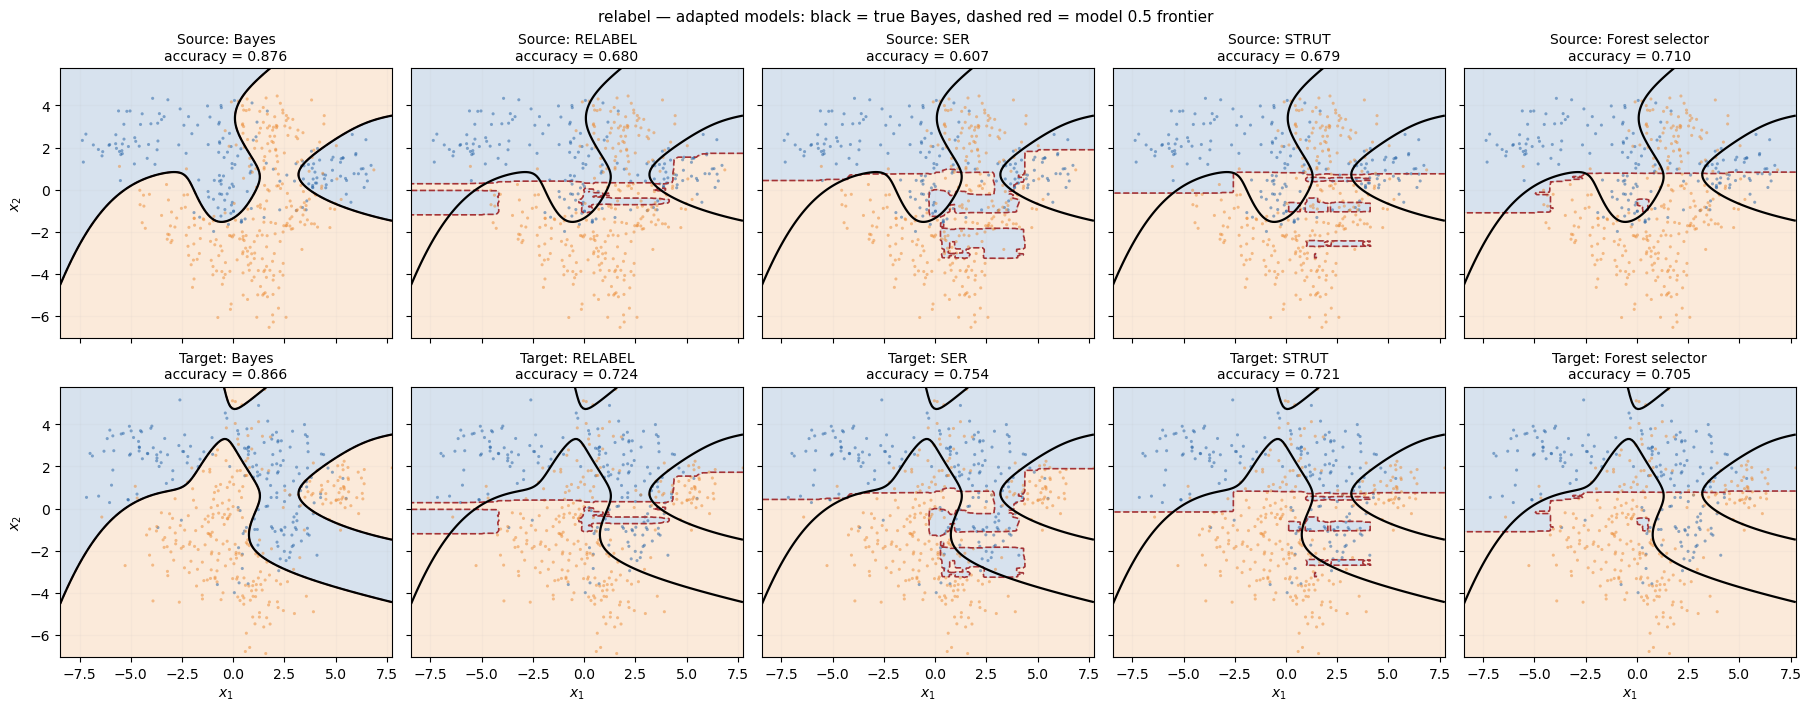

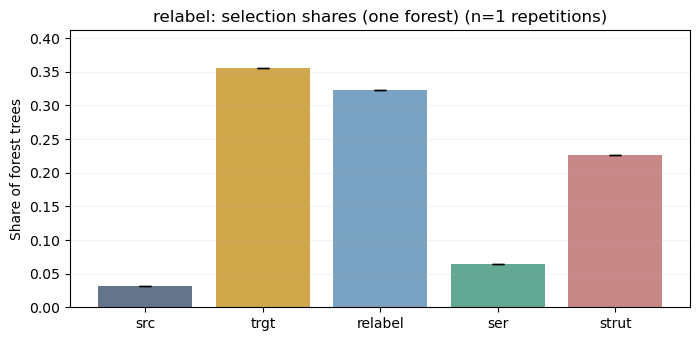

src=keep source; trgt=learn target; relab=change leaves; ser=expand/reduce; strut=adjust split conditions.


In [58]:
transferred_models = {}
selection_indices = None

if HAVE_ADAPT:
    for algorithm in ('relabel', 'ser', 'strut'):
        try:
            TransferClass = (TransferTreeClassifier if MODEL_KIND == 'tree'
                             else TransferForestClassifier)
            adapted = TransferClass(
                estimator=copy.deepcopy(source_model),
                algo=algorithm, copy=True, verbose=0, random_state=RANDOM_SEED
            )
            fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )
            
            adapted.fit(Xt_train, yt_train, **fit_params) 
            transferred_models[algorithm.upper()] = adapted.estimator_
        except Exception as exc:
            print(f'{algorithm.upper()} failed: {type(exc).__name__}: {exc}')

    if MODEL_KIND == 'forest':
        try:
            selector = TransferForestSelector(
                estimator=copy.deepcopy(source_model),
                algorithms=ALGORITHMS, copy=True, verbose=0,
                random_state=RANDOM_SEED
            )
            selector.model_selection(Xt_train, yt_train,
                                     score_type='auc', oob_=True)
            transferred_models['Forest selector'] = selector.STRF_model.estimator_
            selection_indices = np.asarray(selector.STRF_indexes, dtype=int)
        except Exception as exc:
            print(f'Forest selector failed: {type(exc).__name__}: {exc}')
else:
    print('ADAPT missing: relabel/SER/STRUT/selector NOT evaluated.')

transfer_scores = []
for label, predictor in transferred_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    transfer_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))

all_case_scores = pd.DataFrame(baseline_scores + transfer_scores)
all_case_scores.insert(0, 'scenario', SCENARIO)
SCENARIO_SCORES.extend(all_case_scores.to_dict('records'))
display(all_case_scores.round(3))
all_case_scores.to_csv(RESULTS / f'{SCENARIO}_scores.csv', index=False)

if transferred_models:
    plot_predictions(transferred_models, Xs_test, ys_test, Xt_test, yt_test,
                     source_spec, target_spec, SCENARIO + ' — adapted models',
                     save=RESULTS / f'{SCENARIO}_03_transferred.png')

    # Change to plot the training data :
    #plot_predictions(transferred_models, Xs_test, ys_test, Xt_train, yt_train,
    #                 source_spec, target_spec, SCENARIO + ' — adapted models',
    #                 save=RESULTS / f'{SCENARIO}_03_transferred.png')

if MODEL_KIND == 'tree' and PLOT_TREE_DIAGRAMS:
    for algorithm, predictor in transferred_models.items():
        if hasattr(predictor, 'tree_'):
            changes = plot_tree_diff(source_model, predictor,
                title=f'{SCENARIO}: source → {algorithm}',
                max_depth=TREE_PLOT_DEPTH,
                save=RESULTS / f'{SCENARIO}_{algorithm.lower()}_tree.png')
            print(f'{algorithm}: {len(changes)} matched paths changed; ' +
                  'solid red=structure, dashed red=threshold, amber=leaf class')

if MODEL_KIND == 'forest' and selection_indices is not None:
    plot_selection_frequencies([selection_indices], ALGORITHMS,
        f'{SCENARIO}: selection shares (one forest)',
        save=RESULTS / f'{SCENARIO}_selector.png')
    print('src=keep source; trgt=learn target; relab=change leaves; '
          'ser=expand/reduce; strut=adjust split conditions.')

**D. Repeat the experiment on fresh samples from the same distributions.** Change `N_REPETITIONS` in this scenario’s settings. Each repetition redraws source/target training **and** held-out test data, fits all baseline and ADAPT models from scratch, and computes paired target scores. The single-run prediction figures above remain as an illustration; the table below is the average over repetitions. Forest method-selection bars are also averaged over repetitions.

relabel: 10 newly sampled training/test realizations
Held-out accuracy: mean ± SD across independent draws


,method,n_runs,source_mean,source_std,target_mean,target_std
0,Forest selector,10,0.579,0.048,0.775,0.040
1,Pooled (no adaptation),10,0.832,0.010,0.548,0.020
2,RELABEL,10,0.592,0.047,0.779,0.040
3,SER,10,0.547,0.032,0.775,0.027
4,STRUT,10,0.570,0.055,0.749,0.045
5,Source-only,10,0.836,0.010,0.543,0.017
6,Target-only,10,0.568,0.071,0.738,0.054


Paired transfer improvements; > 0 means better than BOTH baselines in that repetition


,method,mean_gain_vs_best_baseline,sd_gain,fraction_positive,mean_gain_vs_pooling,n_paired
0,Forest selector,0.037,0.045,0.9,0.228,10
1,RELABEL,0.041,0.036,0.8,0.232,10
2,SER,0.036,0.050,0.8,0.227,10
3,STRUT,0.011,0.032,0.7,0.202,10


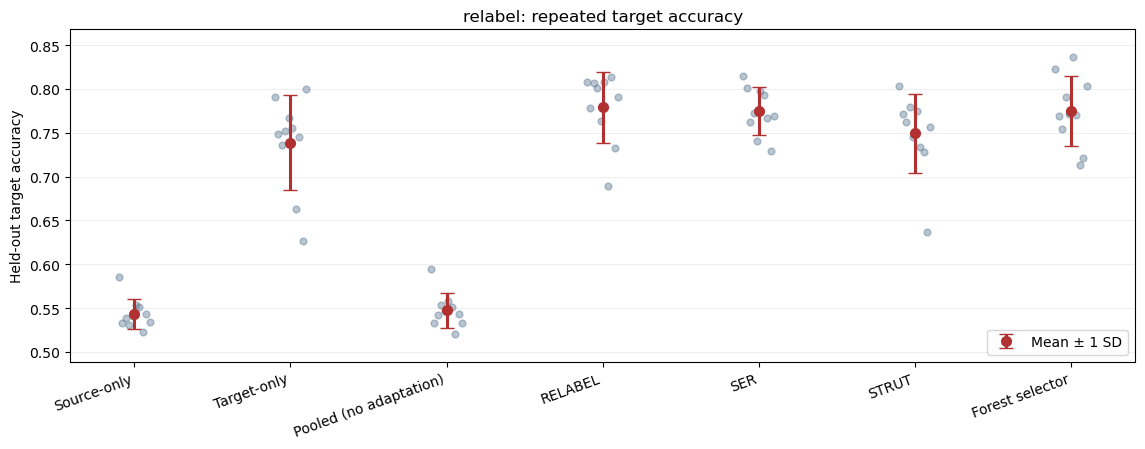

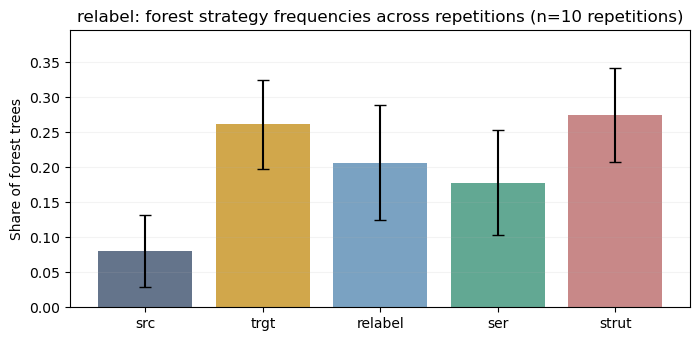

In [61]:
# Restore this section's recorded settings, even if other sections ran afterward.
SCENARIO = 'relabel'
_rep_cfg = SCENARIO_CONFIGS[SCENARIO]
SCENARIO_PARAMS = copy.deepcopy(_rep_cfg['params'])
STRENGTH = _rep_cfg['strength']
SOURCE_N, TARGET_N = _rep_cfg['source_n'], _rep_cfg['target_n']
SOURCE_TEST_N, TARGET_TEST_N = _rep_cfg['source_test_n'], _rep_cfg['target_test_n']
SEED = _rep_cfg['seed']
RUN_REPETITIONS = _rep_cfg['run_repetitions']
N_REPETITIONS = _rep_cfg['n_repetitions']

# Independent draws from the SAME fixed source and target distributions.
# This is separate from the illustrative single-run plots above.
# Every repetition re-draws BOTH labeled training sets and BOTH held-out test sets.
repeated_rows = []
repeated_selections = []
failed_adapt = []

if RUN_REPETITIONS:
    for rep in range(N_REPETITIONS):
        rep_seed = SEED + 100_000 + 10 * rep

        Xs_rep, ys_rep, _, _ = sample_from_distribution(
            source_spec, SOURCE_N, seed=rep_seed)
        Xs_eval, ys_eval, _, _ = sample_from_distribution(
            source_spec, SOURCE_TEST_N, seed=rep_seed + 1)
        Xt_rep, yt_rep, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_N, seed=rep_seed + 2,
            strength=STRENGTH, params=SCENARIO_PARAMS)
        Xt_eval, yt_eval, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_TEST_N, seed=rep_seed + 3,
            strength=STRENGTH, params=SCENARIO_PARAMS)

        # Baseline fits — exactly the SAME datasets and test samples per repetition.
        src_rep_model = clone(base_estimator)
        src_rep_model.fit(Xs_rep, ys_rep)
        tgt_rep_model = clone(base_estimator)
        tgt_rep_model.fit(Xt_rep, yt_rep)
        pooled_rep_model = clone(base_estimator)
        pooled_rep_model.fit(np.vstack((Xs_rep, Xt_rep)), np.r_[ys_rep, yt_rep])
        rep_models = {
            'Source-only': src_rep_model,
            'Target-only': tgt_rep_model,
            'Pooled (no adaptation)': pooled_rep_model,
        }

        # Supervised ADAPT methods — use the FITTED SOURCE model and labeled TARGET data.
        if HAVE_ADAPT:
            for algo in ('relabel', 'ser', 'strut'):
                try:
                    cls = TransferTreeClassifier if MODEL_KIND == 'tree' else TransferForestClassifier
                    adapted = cls(estimator=copy.deepcopy(src_rep_model), algo=algo,
                                  copy=True, verbose=0, random_state=RANDOM_SEED)
                    
                    fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )            
                    adapted.fit(Xt_rep, yt_rep, **fit_params) 
                    
                    rep_models[algo.upper()] = adapted.estimator_
                except Exception as exc:
                    failed_adapt.append((rep, algo, type(exc).__name__, str(exc)[:120]))

            if MODEL_KIND == 'forest':
                try:
                    selector = TransferForestSelector(
                        estimator=copy.deepcopy(src_rep_model), algorithms=ALGORITHMS,
                        copy=True, verbose=0, random_state=RANDOM_SEED,list_alg_args=LIST_ALG_ARGS)
                    selector.model_selection(Xt_rep, yt_rep, score_type='auc', oob_=True)
                    rep_models['Forest selector'] = selector.STRF_model.estimator_
                    repeated_selections.append(np.asarray(selector.STRF_indexes, dtype=int))
                except Exception as exc:
                    failed_adapt.append((rep, 'selector', type(exc).__name__, str(exc)[:120]))

        # Paired evaluation: all methods share each repetition's held-out samples.
        for name, fitted_model in rep_models.items():
            repeated_rows.append({
                'scenario': SCENARIO, 'rep': rep, 'seed': rep_seed, 'method': name,
                'source_accuracy': accuracy_score(ys_eval, fitted_model.predict(Xs_eval)),
                'target_accuracy': accuracy_score(yt_eval, fitted_model.predict(Xt_eval)),
            })

    repeated_df = pd.DataFrame(repeated_rows)
    repeated_df.to_csv(RESULTS / f'{SCENARIO}_repeated_scores.csv', index=False)

    # Mean ± SD across random draws; these are NOT scores from the example plots.
    repeated_summary = (repeated_df.groupby('method')
        .agg(n_runs=('target_accuracy', 'count'),
             source_mean=('source_accuracy', 'mean'),
             source_std=('source_accuracy', 'std'),
             target_mean=('target_accuracy', 'mean'),
             target_std=('target_accuracy', 'std'))
        .reset_index())

    # Per-repetition gain over the better of source-only and target-only.
    paired = repeated_df.pivot(index='rep', columns='method', values='target_accuracy')
    best_base = paired[['Source-only', 'Target-only']].max(axis=1)
    gain_rows = []
    for name in paired.columns:
        if name in ('Source-only', 'Target-only', 'Pooled (no adaptation)'):
            continue
        gain = (paired[name] - best_base).dropna()
        pool_gain = (paired[name] - paired['Pooled (no adaptation)']).dropna()
        gain_rows.append({
            'method': name, 'mean_gain_vs_best_baseline': gain.mean(),
            'sd_gain': gain.std(), 'fraction_positive': (gain > 0).mean(),
            'mean_gain_vs_pooling': pool_gain.mean(), 'n_paired': len(gain),
        })
    gains_df = pd.DataFrame(gain_rows)

    print(f'{SCENARIO}: {N_REPETITIONS} newly sampled training/test realizations')
    print('Held-out accuracy: mean ± SD across independent draws')
    display(repeated_summary.round(3))
    if not gains_df.empty:
        print('Paired transfer improvements; > 0 means better than BOTH baselines in that repetition')
        display(gains_df.round(3))
        gains_df.to_csv(RESULTS / f'{SCENARIO}_paired_gains.csv', index=False)
    # Replace this section's previous summary when rerunning just this block.
    SCENARIO_REPEAT_SUMMARIES[:] = [r for r in SCENARIO_REPEAT_SUMMARIES
                                    if r['scenario'] != SCENARIO]
    SCENARIO_REPEAT_SUMMARIES.extend(
        [dict(scenario=SCENARIO, **row) for row in repeated_summary.to_dict('records')])

    plot_repeated_accuracy(repeated_df, title=f'{SCENARIO}: repeated target accuracy',
        save=RESULTS / f'{SCENARIO}_04_repeated_accuracy.png')

    if MODEL_KIND == 'forest' and repeated_selections:
        plot_selection_frequencies(repeated_selections, ALGORITHMS,
            f'{SCENARIO}: forest strategy frequencies across repetitions',
            save=RESULTS / f'{SCENARIO}_05_repeated_selector.png')

    if failed_adapt:
        print(f'ADAPT fitting failures: {len(failed_adapt)}. First examples:')
        display(pd.DataFrame(failed_adapt, columns=['rep','algo','error_type','message']).head(5))
else:
    print('Repetitions disabled for this scenario. Set RUN_REPETITIONS=True above.')


## 6. Small localized mixed changes

Independent, *small* cluster edits: one translation, one rotation, one anisotropic standard-deviation change, and one mixture reweighting. No global flattening of the distribution.

**A. Edit the settings below and rerun this section only.**

In [63]:
SCENARIO = 'mixed'
SCENARIO_PARAMS = {

    "add_remove": {
        'remove': [6],
        'add': [{
            'mean': [-1.85, 3.50],
            'cov_params': [0.74, 0.47, 26.0],  
            'weight': 0.10,                   
            'label': 1,
            'regression_base_level': 0.40,
            'regression_local_amplitude': 0.15,
            'regression_gradient_angle_deg': 22.0,
        },
        {
            'mean': [1, -3],
            'cov_params': [0.74, 0.47, 26.0],  
            'weight': 0.20,                    
            'label': 0,
            'regression_base_level': 0.40,
            'regression_local_amplitude': 0.15,
            'regression_gradient_angle_deg': 22.0,
        }],
    },


    "translation": {

        'shifts': {
            0: [-2,-2],
            3: [-2,-2],
            5: [-2,-2],
            6: [-2,-2],
            
            1: [-3, -.5], 
            2: [-1.4, -3],  
            4: [0, -3.1],  
        }

    },
}

STRENGTH = 1.0  
SOURCE_N = 500
TARGET_N = 50
SOURCE_TEST_N = 3000
TARGET_TEST_N = 3000

RUN_REPETITIONS = True
N_REPETITIONS = 10     # Increase to 20–30 for more stable uncertainty estimates
SEED = RANDOM_SEED + 6_000

SCENARIO_CONFIGS[SCENARIO] = dict(
    params=copy.deepcopy(SCENARIO_PARAMS), strength=STRENGTH,
    source_n=SOURCE_N, target_n=TARGET_N,
    source_test_n=SOURCE_TEST_N, target_test_n=TARGET_TEST_N, seed=SEED,
    n_repetitions=N_REPETITIONS, run_repetitions=RUN_REPETITIONS
)
print('Selected configuration:', SCENARIO_CONFIGS[SCENARIO])

Selected configuration: {'params': {'add_remove': {'remove': [6], 'add': [{'mean': [-1.85, 3.5], 'cov_params': [0.74, 0.47, 26.0], 'weight': 0.1, 'label': 1, 'regression_base_level': 0.4, 'regression_local_amplitude': 0.15, 'regression_gradient_angle_deg': 22.0}, {'mean': [1, -3], 'cov_params': [0.74, 0.47, 26.0], 'weight': 0.2, 'label': 0, 'regression_base_level': 0.4, 'regression_local_amplitude': 0.15, 'regression_gradient_angle_deg': 22.0}]}, 'translation': {'shifts': {0: [-2, -2], 3: [-2, -2], 5: [-2, -2], 6: [-2, -2], 1: [-3, -0.5], 2: [-1.4, -3], 4: [0, -3.1]}}}, 'strength': 1.0, 'source_n': 500, 'target_n': 50, 'source_test_n': 3000, 'target_test_n': 3000, 'seed': 20267102, 'n_repetitions': 10, 'run_repetitions': True}


**B. Generate data, visualize both domains, train and evaluate the source-only and target-only baselines.** No transfer occurs in this cell.

Exact target edits:
  • STAGE 1 — Cluster addition/removal
  • Remove C6 (class 1)
  • Add C7: class=1, μ=[-1.85, 3.5], axes/angle=[0.74, 0.47, 26.0], raw weight=0.1
  • Add C8: class=0, μ=[1, -3], axes/angle=[0.74, 0.47, 26.0], raw weight=0.2
  • STAGE 2 — Cluster translations
  • C0: Δμ=(-2.00, -2.00)
  • C3: Δμ=(-2.00, -2.00)
  • C5: Δμ=(-2.00, -2.00)
  • C6: Δμ=(-2.00, -2.00)
  • C1: Δμ=(-3.00, -0.50)
  • C2: Δμ=(-1.40, -3.00)
  • C4: Δμ=(+0.00, -3.10)


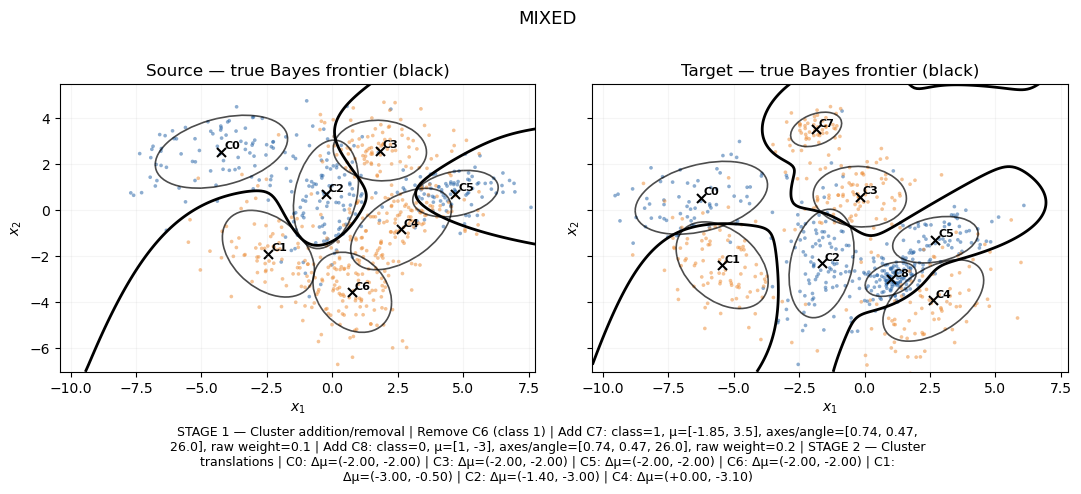

Held-out baseline scores:


,method,source_accuracy,target_accuracy
0,Source-only,0.840,0.396
1,Target-only,0.332,0.672
2,Pooled (no adaptation),0.842,0.399


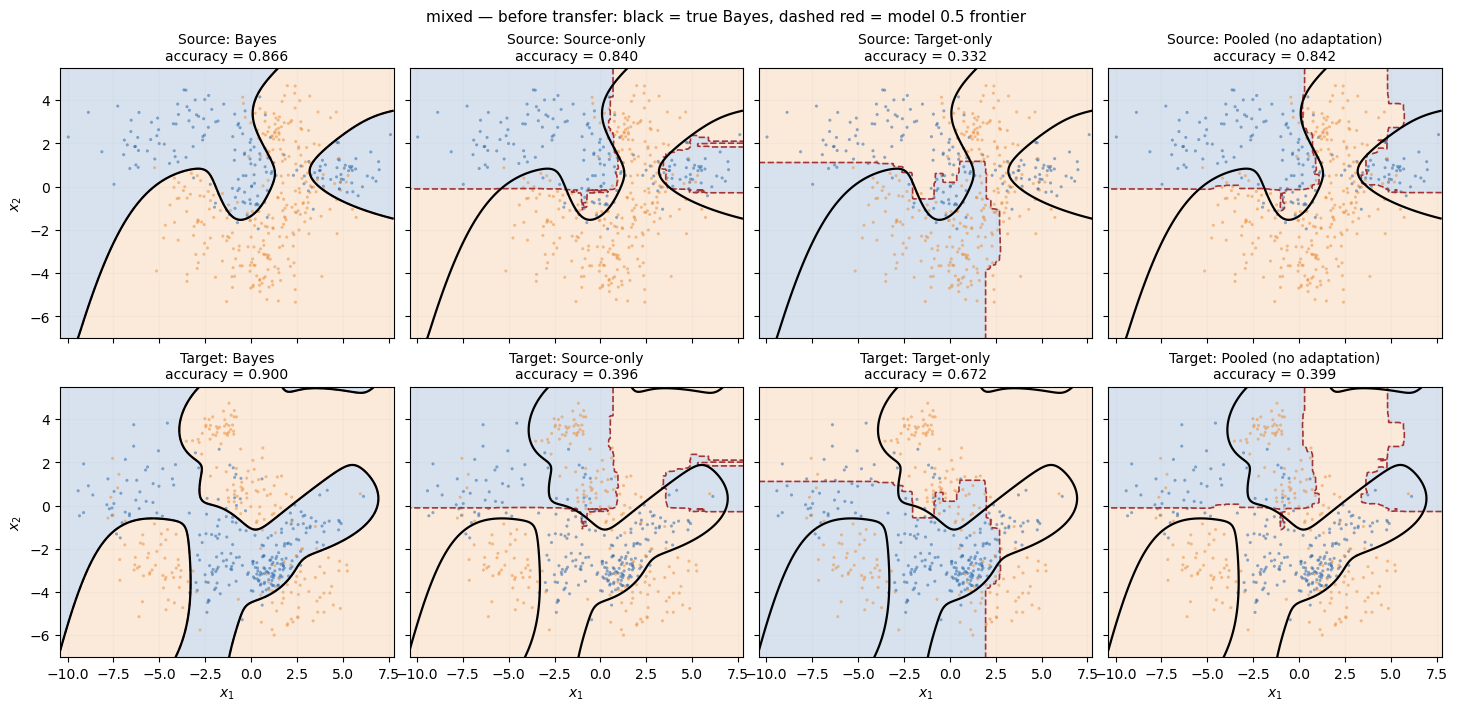

In [66]:
# Independent source and target draws from the saved probability laws.
Xs_train, ys_train, _, cs_train = sample_from_distribution(source_spec, SOURCE_N, seed=SEED)
Xs_test, ys_test, _, cs_test = sample_from_distribution(source_spec, SOURCE_TEST_N, seed=SEED + 1)
Xt_train, yt_train, _, ct_train, target_spec, notes = sample_target(
    source_spec, SCENARIO, TARGET_N, seed=SEED + 2,
    strength=STRENGTH, params=SCENARIO_PARAMS
)
Xt_test, yt_test, _, ct_test, _, _ = sample_target(
    source_spec, SCENARIO, TARGET_TEST_N, seed=SEED + 3,
    strength=STRENGTH, params=SCENARIO_PARAMS
)

print('Exact target edits:')
for note in notes:
    print('  •', note)
plot_domains(Xs_test, ys_test, Xt_test, yt_test, source_spec, target_spec,
             SCENARIO, notes, save=RESULTS / f'{SCENARIO}_01_domains.png')

# Three independent fitted controls; the pooled model is a useful diagnostic.
source_model = clone(base_estimator)
source_model.fit(Xs_train, ys_train)

target_model = clone(base_estimator)
target_model.fit(Xt_train, yt_train)                  # target LABELS are used

pooled_model = clone(base_estimator)
pooled_model.fit(np.vstack([Xs_train, Xt_train]), np.r_[ys_train, yt_train])

baseline_models = {'Source-only': source_model,
                   'Target-only': target_model,
                   'Pooled (no adaptation)': pooled_model}

baseline_scores = []
for label, predictor in baseline_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    baseline_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))
print('Held-out baseline scores:')
display(pd.DataFrame(baseline_scores).round(3))

# Bayes frontier + baseline decision regions, on SOURCE and TARGET.
plot_predictions(baseline_models, Xs_test, ys_test, Xt_test, yt_test,
                 source_spec, target_spec, SCENARIO + ' — before transfer',
                 save=RESULTS / f'{SCENARIO}_02_baselines.png')

**C. Adapt the pretrained source model using labeled target training data; evaluate on untouched test samples.** These are the actual ADAPT calls, not helper wrappers.

,scenario,method,source_accuracy,target_accuracy
0,mixed,Source-only,0.840,0.396
1,mixed,Target-only,0.332,0.672
2,mixed,Pooled (no adaptation),0.842,0.399
3,mixed,RELABEL,0.337,0.755
4,mixed,SER,0.342,0.743
5,mixed,STRUT,0.354,0.716
6,mixed,Forest selector,0.359,0.730


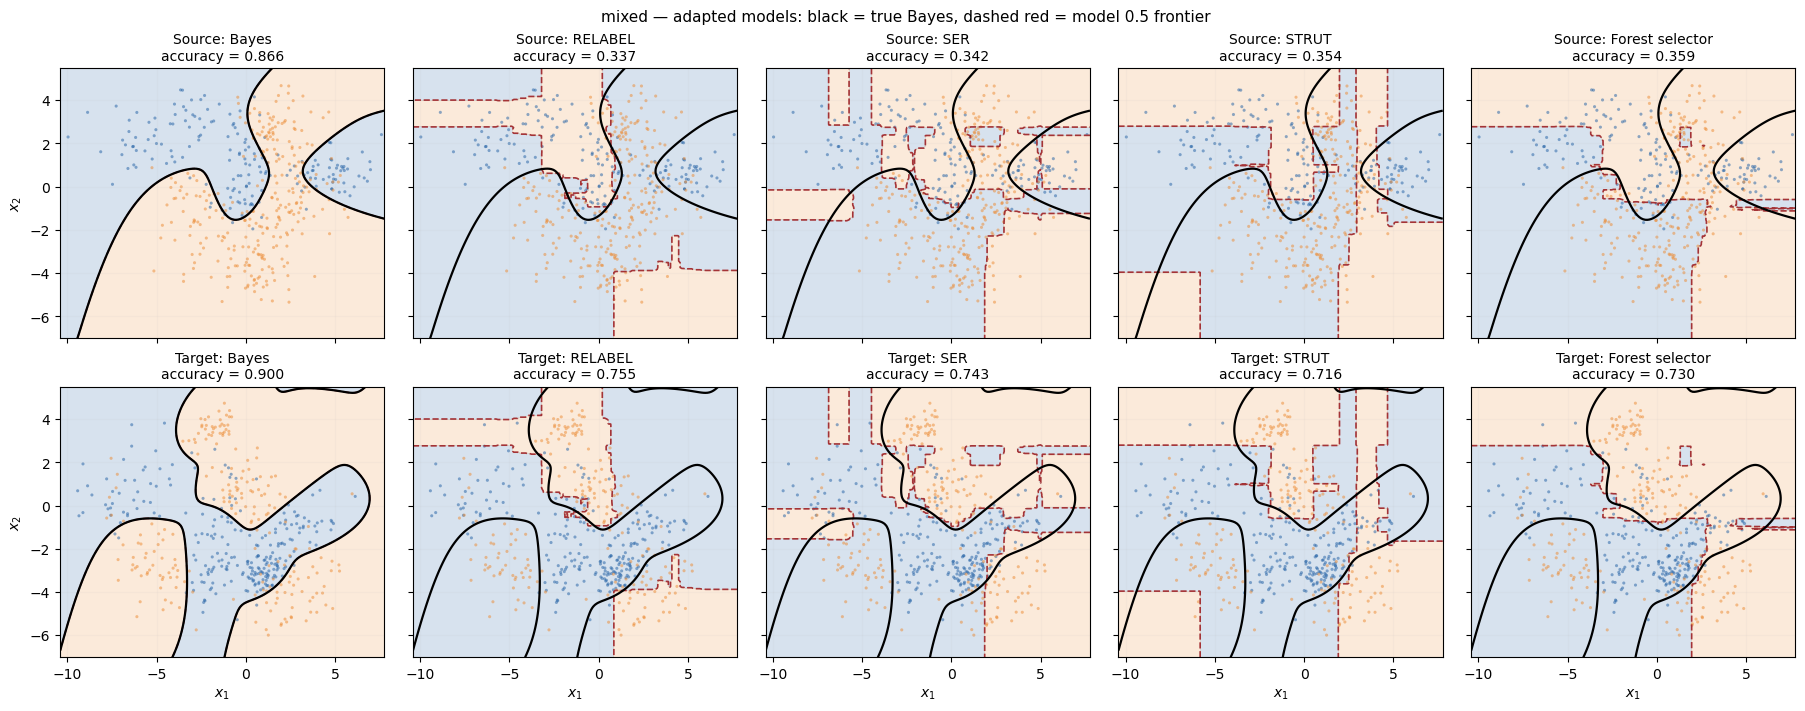

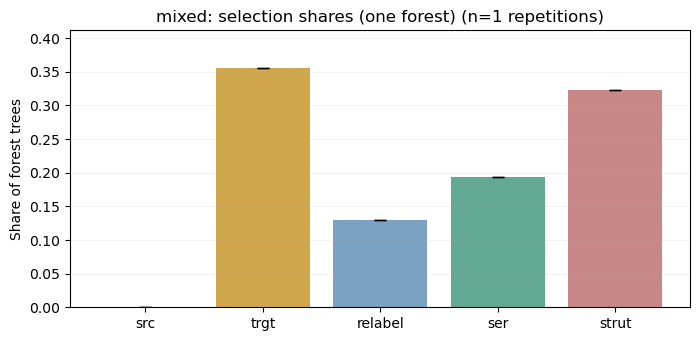

src=keep source; trgt=learn target; relab=change leaves; ser=expand/reduce; strut=adjust split conditions.


In [69]:
transferred_models = {}
selection_indices = None

if HAVE_ADAPT:
    for algorithm in ('relabel', 'ser', 'strut'):
        try:
            TransferClass = (TransferTreeClassifier if MODEL_KIND == 'tree'
                             else TransferForestClassifier)
            adapted = TransferClass(
                estimator=copy.deepcopy(source_model),
                algo=algorithm, copy=True, verbose=0, random_state=RANDOM_SEED
            )
            fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )
            
            adapted.fit(Xt_train, yt_train, **fit_params) 
            transferred_models[algorithm.upper()] = adapted.estimator_
        except Exception as exc:
            print(f'{algorithm.upper()} failed: {type(exc).__name__}: {exc}')

    if MODEL_KIND == 'forest':
        try:
            selector = TransferForestSelector(
                estimator=copy.deepcopy(source_model),
                algorithms=ALGORITHMS, copy=True, verbose=0,
                random_state=RANDOM_SEED
            )
            selector.model_selection(Xt_train, yt_train,
                                     score_type='auc', oob_=True)
            transferred_models['Forest selector'] = selector.STRF_model.estimator_
            selection_indices = np.asarray(selector.STRF_indexes, dtype=int)
        except Exception as exc:
            print(f'Forest selector failed: {type(exc).__name__}: {exc}')
else:
    print('ADAPT missing: relabel/SER/STRUT/selector NOT evaluated.')

transfer_scores = []
for label, predictor in transferred_models.items():
    pred_source = predictor.predict(Xs_test)
    pred_target = predictor.predict(Xt_test)
    transfer_scores.append(dict(method=label,
        source_accuracy=accuracy_score(ys_test, pred_source),
        target_accuracy=accuracy_score(yt_test, pred_target)))

all_case_scores = pd.DataFrame(baseline_scores + transfer_scores)
all_case_scores.insert(0, 'scenario', SCENARIO)
SCENARIO_SCORES.extend(all_case_scores.to_dict('records'))
display(all_case_scores.round(3))
all_case_scores.to_csv(RESULTS / f'{SCENARIO}_scores.csv', index=False)

if transferred_models:
    plot_predictions(transferred_models, Xs_test, ys_test, Xt_test, yt_test,
                     source_spec, target_spec, SCENARIO + ' — adapted models',
                     save=RESULTS / f'{SCENARIO}_03_transferred.png')

    # Change to plot the training data :
    #plot_predictions(transferred_models, Xs_test, ys_test, Xt_train, yt_train,
    #                 source_spec, target_spec, SCENARIO + ' — adapted models',
    #                 save=RESULTS / f'{SCENARIO}_03_transferred.png')

if MODEL_KIND == 'tree' and PLOT_TREE_DIAGRAMS:
    for algorithm, predictor in transferred_models.items():
        if hasattr(predictor, 'tree_'):
            changes = plot_tree_diff(source_model, predictor,
                title=f'{SCENARIO}: source → {algorithm}',
                max_depth=TREE_PLOT_DEPTH,
                save=RESULTS / f'{SCENARIO}_{algorithm.lower()}_tree.png')
            print(f'{algorithm}: {len(changes)} matched paths changed; ' +
                  'solid red=structure, dashed red=threshold, amber=leaf class')

if MODEL_KIND == 'forest' and selection_indices is not None:
    plot_selection_frequencies([selection_indices], ALGORITHMS,
        f'{SCENARIO}: selection shares (one forest)',
        save=RESULTS / f'{SCENARIO}_selector.png')
    print('src=keep source; trgt=learn target; relab=change leaves; '
          'ser=expand/reduce; strut=adjust split conditions.')

**D. Repeat the experiment on fresh samples from the same distributions.** Change `N_REPETITIONS` in this scenario’s settings. Each repetition redraws source/target training **and** held-out test data, fits all baseline and ADAPT models from scratch, and computes paired target scores. The single-run prediction figures above remain as an illustration; the table below is the average over repetitions. Forest method-selection bars are also averaged over repetitions.

mixed: 10 newly sampled training/test realizations
Held-out accuracy: mean ± SD across independent draws


,method,n_runs,source_mean,source_std,target_mean,target_std
0,Forest selector,10,0.389,0.067,0.722,0.050
1,Pooled (no adaptation),10,0.833,0.007,0.411,0.022
2,RELABEL,10,0.355,0.061,0.682,0.025
3,SER,10,0.441,0.045,0.773,0.032
4,STRUT,10,0.371,0.049,0.712,0.036
5,Source-only,10,0.835,0.009,0.401,0.015
6,Target-only,10,0.367,0.058,0.650,0.059


Paired transfer improvements; > 0 means better than BOTH baselines in that repetition


,method,mean_gain_vs_best_baseline,sd_gain,fraction_positive,mean_gain_vs_pooling,n_paired
0,Forest selector,0.071,0.053,0.9,0.311,10
1,RELABEL,0.032,0.045,0.8,0.272,10
2,SER,0.123,0.058,1.0,0.363,10
3,STRUT,0.062,0.042,1.0,0.301,10


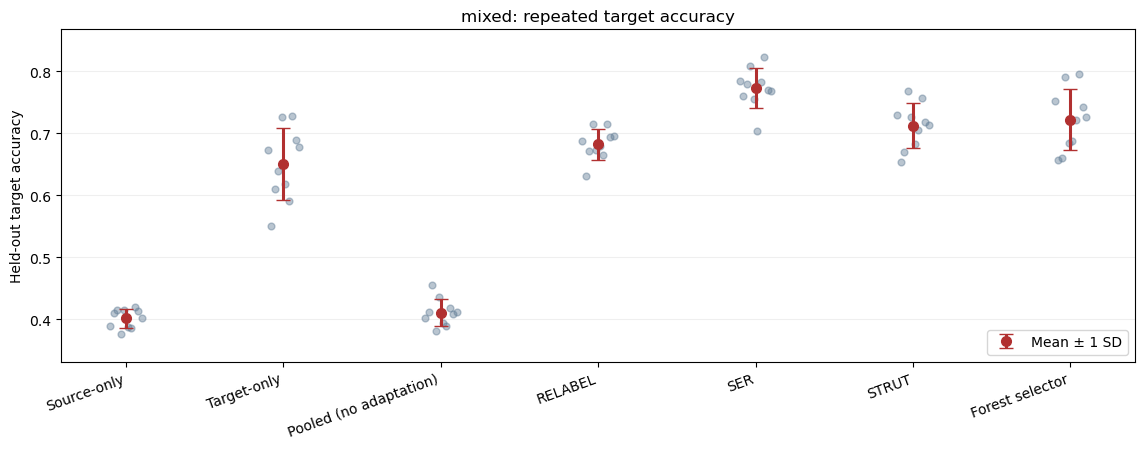

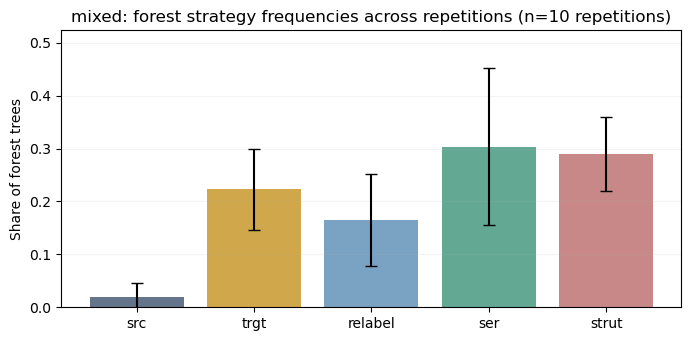

In [72]:
# Restore this section's recorded settings, even if other sections ran afterward.
SCENARIO = 'mixed'
_rep_cfg = SCENARIO_CONFIGS[SCENARIO]
SCENARIO_PARAMS = copy.deepcopy(_rep_cfg['params'])
STRENGTH = _rep_cfg['strength']
SOURCE_N, TARGET_N = _rep_cfg['source_n'], _rep_cfg['target_n']
SOURCE_TEST_N, TARGET_TEST_N = _rep_cfg['source_test_n'], _rep_cfg['target_test_n']
SEED = _rep_cfg['seed']
RUN_REPETITIONS = _rep_cfg['run_repetitions']
N_REPETITIONS = _rep_cfg['n_repetitions']

# Independent draws from the SAME fixed source and target distributions.
# This is separate from the illustrative single-run plots above.
# Every repetition re-draws BOTH labeled training sets and BOTH held-out test sets.
repeated_rows = []
repeated_selections = []
failed_adapt = []

if RUN_REPETITIONS:
    for rep in range(N_REPETITIONS):
        rep_seed = SEED + 100_000 + 10 * rep

        Xs_rep, ys_rep, _, _ = sample_from_distribution(
            source_spec, SOURCE_N, seed=rep_seed)
        Xs_eval, ys_eval, _, _ = sample_from_distribution(
            source_spec, SOURCE_TEST_N, seed=rep_seed + 1)
        Xt_rep, yt_rep, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_N, seed=rep_seed + 2,
            strength=STRENGTH, params=SCENARIO_PARAMS)
        Xt_eval, yt_eval, _, _, _, _ = sample_target(
            source_spec, SCENARIO, TARGET_TEST_N, seed=rep_seed + 3,
            strength=STRENGTH, params=SCENARIO_PARAMS)

        # Baseline fits — exactly the SAME datasets and test samples per repetition.
        src_rep_model = clone(base_estimator)
        src_rep_model.fit(Xs_rep, ys_rep)
        tgt_rep_model = clone(base_estimator)
        tgt_rep_model.fit(Xt_rep, yt_rep)
        pooled_rep_model = clone(base_estimator)
        pooled_rep_model.fit(np.vstack((Xs_rep, Xt_rep)), np.r_[ys_rep, yt_rep])
        rep_models = {
            'Source-only': src_rep_model,
            'Target-only': tgt_rep_model,
            'Pooled (no adaptation)': pooled_rep_model,
        }

        # Supervised ADAPT methods — use the FITTED SOURCE model and labeled TARGET data.
        if HAVE_ADAPT:
            for algo in ('relabel', 'ser', 'strut'):
                try:
                    cls = TransferTreeClassifier if MODEL_KIND == 'tree' else TransferForestClassifier
                    adapted = cls(estimator=copy.deepcopy(src_rep_model), algo=algo,
                                  copy=True, verbose=0, random_state=RANDOM_SEED)

                    fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )            
                    adapted.fit(Xt_rep, yt_rep, **fit_params) 
                    
                    rep_models[algo.upper()] = adapted.estimator_
                except Exception as exc:
                    failed_adapt.append((rep, algo, type(exc).__name__, str(exc)[:120]))

            if MODEL_KIND == 'forest':
                try:
                    selector = TransferForestSelector(
                        estimator=copy.deepcopy(src_rep_model), algorithms=ALGORITHMS,
                        copy=True, verbose=0, random_state=RANDOM_SEED,list_alg_args=LIST_ALG_ARGS)
                    selector.model_selection(Xt_rep, yt_rep, score_type='auc', oob_=True)
                    rep_models['Forest selector'] = selector.STRF_model.estimator_
                    repeated_selections.append(np.asarray(selector.STRF_indexes, dtype=int))
                except Exception as exc:
                    failed_adapt.append((rep, 'selector', type(exc).__name__, str(exc)[:120]))

        # Paired evaluation: all methods share each repetition's held-out samples.
        for name, fitted_model in rep_models.items():
            repeated_rows.append({
                'scenario': SCENARIO, 'rep': rep, 'seed': rep_seed, 'method': name,
                'source_accuracy': accuracy_score(ys_eval, fitted_model.predict(Xs_eval)),
                'target_accuracy': accuracy_score(yt_eval, fitted_model.predict(Xt_eval)),
            })

    repeated_df = pd.DataFrame(repeated_rows)
    repeated_df.to_csv(RESULTS / f'{SCENARIO}_repeated_scores.csv', index=False)

    # Mean ± SD across random draws; these are NOT scores from the example plots.
    repeated_summary = (repeated_df.groupby('method')
        .agg(n_runs=('target_accuracy', 'count'),
             source_mean=('source_accuracy', 'mean'),
             source_std=('source_accuracy', 'std'),
             target_mean=('target_accuracy', 'mean'),
             target_std=('target_accuracy', 'std'))
        .reset_index())

    # Per-repetition gain over the better of source-only and target-only.
    paired = repeated_df.pivot(index='rep', columns='method', values='target_accuracy')
    best_base = paired[['Source-only', 'Target-only']].max(axis=1)
    gain_rows = []
    for name in paired.columns:
        if name in ('Source-only', 'Target-only', 'Pooled (no adaptation)'):
            continue
        gain = (paired[name] - best_base).dropna()
        pool_gain = (paired[name] - paired['Pooled (no adaptation)']).dropna()
        gain_rows.append({
            'method': name, 'mean_gain_vs_best_baseline': gain.mean(),
            'sd_gain': gain.std(), 'fraction_positive': (gain > 0).mean(),
            'mean_gain_vs_pooling': pool_gain.mean(), 'n_paired': len(gain),
        })
    gains_df = pd.DataFrame(gain_rows)

    print(f'{SCENARIO}: {N_REPETITIONS} newly sampled training/test realizations')
    print('Held-out accuracy: mean ± SD across independent draws')
    display(repeated_summary.round(3))
    if not gains_df.empty:
        print('Paired transfer improvements; > 0 means better than BOTH baselines in that repetition')
        display(gains_df.round(3))
        gains_df.to_csv(RESULTS / f'{SCENARIO}_paired_gains.csv', index=False)
    # Replace this section's previous summary when rerunning just this block.
    SCENARIO_REPEAT_SUMMARIES[:] = [r for r in SCENARIO_REPEAT_SUMMARIES
                                    if r['scenario'] != SCENARIO]
    SCENARIO_REPEAT_SUMMARIES.extend(
        [dict(scenario=SCENARIO, **row) for row in repeated_summary.to_dict('records')])

    plot_repeated_accuracy(repeated_df, title=f'{SCENARIO}: repeated target accuracy',
        save=RESULTS / f'{SCENARIO}_04_repeated_accuracy.png')

    if MODEL_KIND == 'forest' and repeated_selections:
        plot_selection_frequencies(repeated_selections, ALGORITHMS,
            f'{SCENARIO}: forest strategy frequencies across repetitions',
            save=RESULTS / f'{SCENARIO}_05_repeated_selector.png')

    if failed_adapt:
        print(f'ADAPT fitting failures: {len(failed_adapt)}. First examples:')
        display(pd.DataFrame(failed_adapt, columns=['rep','algo','error_type','message']).head(5))
else:
    print('Repetitions disabled for this scenario. Set RUN_REPETITIONS=True above.')


## 7. Sensitivity experiments — choose one of the six scenarios

The six settings above are saved in `SCENARIO_CONFIGS`. Choose **which** one to study below. You can change the target budgets, shift values and repetitions independently. To change a scenario recipe, edit its earlier parameter cell first.

**Note:** `add_remove` and `relabel` are categorical transformations. For a continuous severity curve, use `covariate`, `translation` or `mixed`.

In [75]:
SWEEP_SCENARIO = 'translation'
SWEEP_PARAMS = copy.deepcopy(SCENARIO_CONFIGS[SWEEP_SCENARIO]['params'])
SWEEP_STRENGTH = SCENARIO_CONFIGS[SWEEP_SCENARIO]['strength']
SWEEP_SOURCE_N = SCENARIO_CONFIGS[SWEEP_SCENARIO]['source_n']
SWEEP_TARGET_N = SCENARIO_CONFIGS[SWEEP_SCENARIO]['target_n']
SWEEP_TARGET_TEST_N = SCENARIO_CONFIGS[SWEEP_SCENARIO]['target_test_n']
BUDGETS = [20,50, 80, 110, 150, 200,300]
STRENGTHS = [0.2,0.35,0.5,0.75,1.0,1.5,2,2.5,3]
REPEATS = 10           # increase to ~20-30 when checking conclusions
RUN_SWEEPS = True    # set True to run time-consuming transfer sweeps

print('Sweep scenario:', SWEEP_SCENARIO, '\nRecipe:', SWEEP_PARAMS,
      '\nSource size:', SWEEP_SOURCE_N, '| Fixed target size for severity:', SWEEP_TARGET_N)

Sweep scenario: translation 
Recipe: {'shifts': {0: [-2, -2], 3: [-2, -2], 5: [-2, -2], 6: [-2, -2], 1: [-3, -0.5], 2: [-1.4, -3], 4: [0, -3.1]}} 
Source size: 500 | Fixed target size for severity: 50


### 7A. More labeled target observations

All four model families are fitted explicitly below. Each seed uses the same test set across predictors. Uncertainty bars show variation across independent draws.

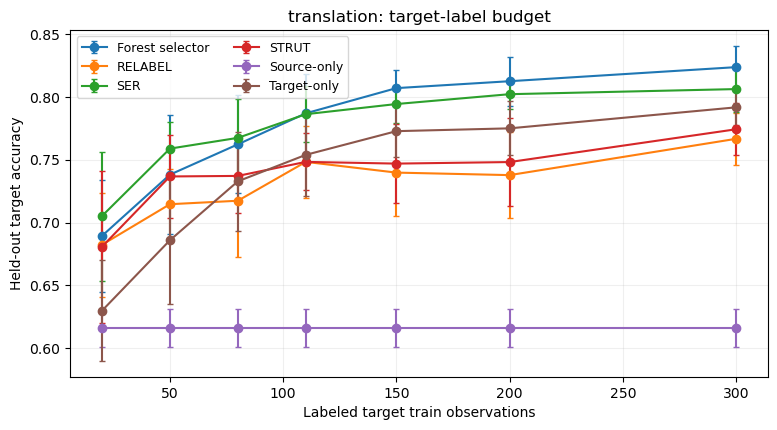

,n_target,method,mean,std
0,20,Forest selector,0.689,0.045
1,20,RELABEL,0.682,0.041
2,20,SER,0.705,0.051
3,20,STRUT,0.681,0.061
4,20,Source-only,0.616,0.015
5,20,Target-only,0.630,0.040
6,50,Forest selector,0.738,0.047
7,50,RELABEL,0.715,0.028
8,50,SER,0.759,0.021
9,50,STRUT,0.737,0.033


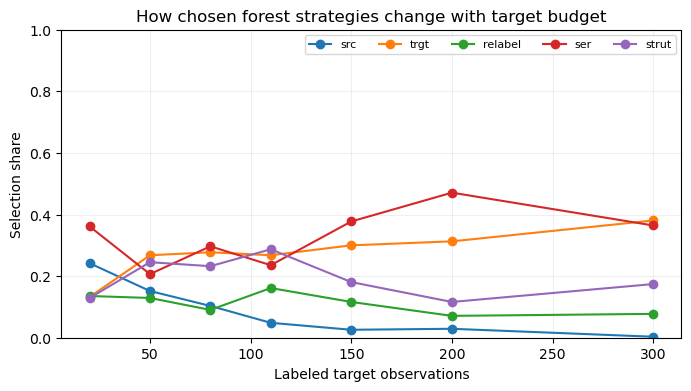

In [78]:
budget_rows = []
budget_selections = {}
if RUN_SWEEPS:
    for n_target in BUDGETS:
        selected = []
        for repetition in range(REPEATS):
            seed = RANDOM_SEED + 300_000 + repetition*10
            Xsr, ysr, _, _ = sample_from_distribution(source_spec, SWEEP_SOURCE_N, seed=seed)
            Xtr, ytr, _, _, _, _ = sample_target(source_spec, SWEEP_SCENARIO,
                n_target, seed=seed+1, strength=SWEEP_STRENGTH, params=SWEEP_PARAMS)
            Xte, yte, _, _, _, _ = sample_target(source_spec, SWEEP_SCENARIO,
                SWEEP_TARGET_TEST_N, seed=seed+2, strength=SWEEP_STRENGTH, params=SWEEP_PARAMS)

            source = clone(base_estimator).fit(Xsr, ysr)
            target = clone(base_estimator).fit(Xtr, ytr)
            pooled = clone(base_estimator).fit(np.vstack([Xsr,Xtr]), np.r_[ysr,ytr])
            #models = {'Source-only': source, 'Target-only': target, 'Pooled': pooled}
            models = {'Source-only': source, 'Target-only': target}
            if HAVE_ADAPT:
                for algorithm in ('relabel','ser','strut'):
                    try:
                        TransferClass = TransferTreeClassifier if MODEL_KIND=='tree' else TransferForestClassifier
                        adapted = TransferClass(estimator=copy.deepcopy(source), algo=algorithm,
                                                copy=True, verbose=0, random_state=RANDOM_SEED)
                        
                        fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )            
                        adapted.fit(Xtr, ytr, **fit_params) 

                        models[algorithm.upper()] = adapted.estimator_
                    except Exception as exc:
                        print(f'Budget {n_target}, {algorithm}: {exc}')
                if MODEL_KIND=='forest':
                    try:
                        selector = TransferForestSelector(estimator=copy.deepcopy(source),
                            algorithms=ALGORITHMS, copy=True, verbose=0, random_state=RANDOM_SEED,list_alg_args=LIST_ALG_ARGS)
                        selector.model_selection(Xtr,ytr,score_type='auc',oob_=True)
                        models['Forest selector'] = selector.STRF_model.estimator_
                        selected.append(np.asarray(selector.STRF_indexes,dtype=int))
                    except Exception as exc:
                        print(f'Budget {n_target}: selector failed: {exc}')
            for label, model in models.items():
                budget_rows.append(dict(n_target=n_target, repetition=repetition,
                                        method=label, target_accuracy=accuracy_score(yte, model.predict(Xte))))
        budget_selections[n_target] = selected

    budget_df = pd.DataFrame(budget_rows)
    summary = budget_df.groupby(['n_target','method']).target_accuracy.agg(['mean','std']).reset_index()
    fig, ax = plt.subplots(figsize=(9,4.5))
    for label, group in summary.groupby('method'):
        ax.errorbar(group.n_target,group['mean'],yerr=group['std'].fillna(0),
                    label=label,marker='o',capsize=2)
    #ax.set_xscale('log',base=2);
    ax.set_xlabel('Labeled target train observations')
    ax.set_ylabel('Held-out target accuracy');ax.set_title(f'{SWEEP_SCENARIO}: target-label budget')
    ax.legend(ncol=2,fontsize=9);ax.grid(alpha=.2)
    plt.show();plt.close(fig)
    display(summary.round(3))
    budget_df.to_csv(RESULTS / f'{SWEEP_SCENARIO}_budget_sweep.csv',index=False)

    if MODEL_KIND=='forest' and HAVE_ADAPT:
        shares = {n:np.stack([np.bincount(ids,minlength=len(ALGORITHMS))/len(ids)
                 for ids in arrays]).mean(axis=0)
                 for n,arrays in budget_selections.items() if arrays}
        if shares:
            fig,ax=plt.subplots(figsize=(8,4))
            for j,label in enumerate(ALGORITHMS):
                ax.plot(list(shares),[v[j] for v in shares.values()],marker='o',label=label)
            #ax.set_xscale('log',base=2);
            ax.set_ylim(0,1)
            ax.set_xlabel('Labeled target observations');ax.set_ylabel('Selection share')
            ax.set_title('How chosen forest strategies change with target budget')
            ax.legend(ncol=5,fontsize=8);ax.grid(alpha=.2)
            plt.show();plt.close(fig)
else:
    print('Sweeps disabled: set RUN_SWEEPS=True in §7.')

### 7B. Increase one declared scenario strength

The same exact base transformations are multiplied by the scalar `strength`; no new random cluster edits are introduced. For categorical changes, compare their *presence or absence* instead of treating the change as continuous.

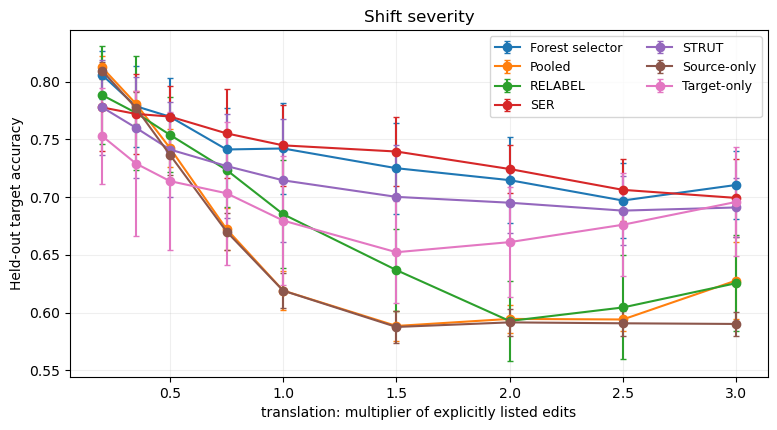

,strength,method,mean,std
0,0.2,Forest selector,0.806,0.021
1,0.2,Pooled,0.812,0.009
2,0.2,RELABEL,0.788,0.042
3,0.2,SER,0.778,0.038
4,0.2,STRUT,0.778,0.041
...,...,...,...,...
58,3.0,RELABEL,0.626,0.042
59,3.0,SER,0.699,0.034
60,3.0,STRUT,0.691,0.026
61,3.0,Source-only,0.590,0.010


In [80]:
shift_rows = []
if RUN_SWEEPS:
    if SWEEP_SCENARIO in ('add_remove','relabel'):
        raise ValueError('Categorical shift: use a 0/1 comparison instead of the continuous STRENGTHS grid.')
    for strength in STRENGTHS:
        for repetition in range(REPEATS):
            seed = RANDOM_SEED + 450_000 + repetition*10
            Xsr, ysr, _, _ = sample_from_distribution(source_spec, SWEEP_SOURCE_N, seed=seed)
            Xtr, ytr, _, _, _, _ = sample_target(source_spec, SWEEP_SCENARIO,
                SWEEP_TARGET_N, seed=seed+1, strength=strength, params=SWEEP_PARAMS)
            Xte, yte, _, _, _, _ = sample_target(source_spec, SWEEP_SCENARIO,
                SWEEP_TARGET_TEST_N, seed=seed+2, strength=strength, params=SWEEP_PARAMS)

            source = clone(base_estimator).fit(Xsr,ysr)
            target = clone(base_estimator).fit(Xtr,ytr)
            pooled = clone(base_estimator).fit(np.vstack([Xsr,Xtr]),np.r_[ysr,ytr])
            models = {'Source-only':source,'Target-only':target,'Pooled':pooled}
            if HAVE_ADAPT:
                for algorithm in ('relabel','ser','strut'):
                    try:
                        TransferClass = TransferTreeClassifier if MODEL_KIND=='tree' else TransferForestClassifier
                        adapted = TransferClass(estimator=copy.deepcopy(source), algo=algorithm,
                                                copy=True, verbose=0, random_state=RANDOM_SEED)
                        
                        fit_params = ( {"max_depth": SER_MAX_DEPTH} if algorithm == "ser" else {} )            
                        adapted.fit(Xtr, ytr, **fit_params) 
                        
                        models[algorithm.upper()] = adapted.estimator_
                    except Exception as exc:
                        print(f'Strength {strength:.2f}, {algorithm}: {exc}')
                if MODEL_KIND=='forest':
                    try:
                        selector = TransferForestSelector(estimator=copy.deepcopy(source),
                            algorithms=ALGORITHMS,copy=True,verbose=0,random_state=RANDOM_SEED,list_alg_args=LIST_ALG_ARGS)
                        selector.model_selection(Xtr,ytr,score_type='auc',oob_=True)
                        models['Forest selector']=selector.STRF_model.estimator_
                    except Exception as exc:
                        print(f'Strength {strength:.2f}: selector failed: {exc}')
            for label,model in models.items():
                shift_rows.append(dict(strength=strength, repetition=repetition,
                    method=label,target_accuracy=accuracy_score(yte,model.predict(Xte))))

    shift_df=pd.DataFrame(shift_rows)
    summary=shift_df.groupby(['strength','method']).target_accuracy.agg(['mean','std']).reset_index()
    fig,ax=plt.subplots(figsize=(9,4.5))
    for label,group in summary.groupby('method'):
        ax.errorbar(group.strength,group['mean'],yerr=group['std'].fillna(0),
                    label=label,marker='o',capsize=2)
    ax.set_xlabel(f'{SWEEP_SCENARIO}: multiplier of explicitly listed edits')
    ax.set_ylabel('Held-out target accuracy');ax.set_title('Shift severity')
    ax.legend(ncol=2,fontsize=9);ax.grid(alpha=.2)
    plt.show();plt.close(fig)
    display(summary.round(3))
    shift_df.to_csv(RESULTS / f'{SWEEP_SCENARIO}_strength_sweep.csv',index=False)
else:
    print('Sweeps disabled: set RUN_SWEEPS=True in §7.')

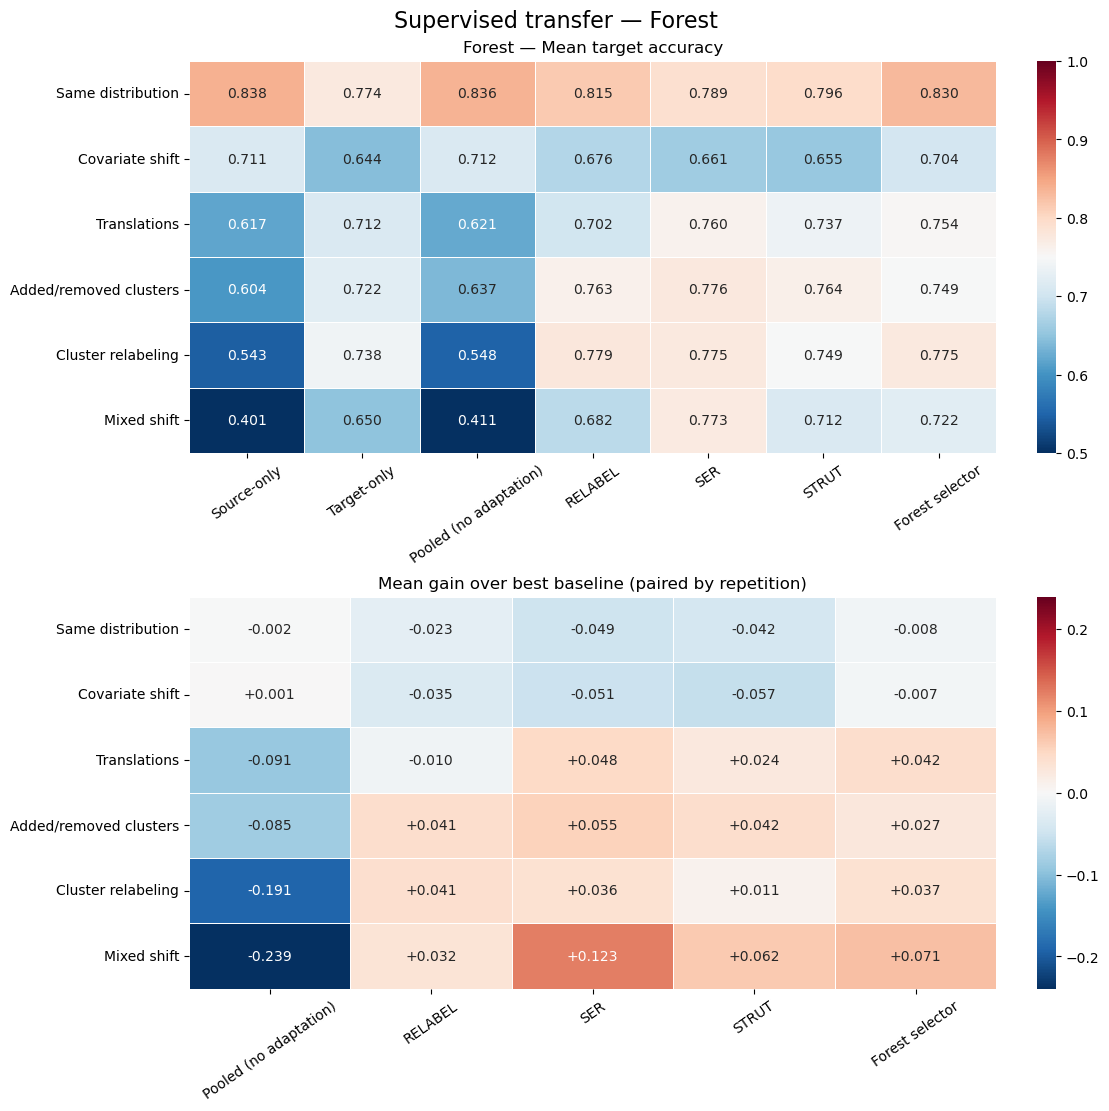

In [82]:
import seaborn as sns 

def plot_scenario_heatmaps(results_dir, model_kind="forest",
                           metric="target_accuracy"):

    SCENARIOS = [
        "same", "covariate", "translation",
        "add_remove", "relabel", "mixed"
    ]

    SCENARIO_LABELS = {
        "same": "Same distribution",
        "covariate": "Covariate shift",
        "translation": "Translations",
        "add_remove": "Added/removed clusters",
        "relabel": "Cluster relabeling",
        "mixed": "Mixed shift",
    }

    METHOD_ORDER = [
        "Source-only",
        "Target-only",
        "Pooled (no adaptation)",
        "RELABEL",
        "SER",
        "STRUT",
        "Forest selector",
    ]

    # -------------------------------------------------
    # 1. Load repeated results from every scenario
    # -------------------------------------------------
    frames = []

    for scenario in SCENARIOS:
        path = Path(results_dir) / f"{scenario}_repeated_scores.csv"

        if path.exists():
            df = pd.read_csv(path)
            df["scenario"] = scenario
            frames.append(df)
        else:
            print(f"Missing results: {scenario}")

    if not frames:
        raise ValueError("No repeated-score CSV files found.")

    scores = pd.concat(frames, ignore_index=True)

    # Normalize older method naming
    scores["method"] = scores["method"].replace({
        "RELAB": "RELABEL"
    })

    scores[metric] = pd.to_numeric(scores[metric], errors="coerce")
    scores = scores.dropna(subset=[metric])

    # -------------------------------------------------
    # 2. One row per scenario AND repetition
    # -------------------------------------------------
    pivot_rep = scores.pivot_table(
        index=["scenario", "rep"],
        columns="method",
        values=metric,
        aggfunc="mean"
    )

    methods = [
        m for m in METHOD_ORDER if m in pivot_rep.columns
    ]

    scenarios = [
        s for s in SCENARIOS
        if s in pivot_rep.index.get_level_values("scenario")
    ]

    # -------------------------------------------------
    # 3. Absolute performance (mean across repeats)
    # -------------------------------------------------
    absolute = pivot_rep.groupby(level="scenario").mean()

    absolute = absolute.reindex(
        index=scenarios,
        columns=methods
    ).dropna(axis=1, how="all")

    # -------------------------------------------------
    # 4. Paired gains over the best baseline
    # -------------------------------------------------
    baselines = ["Source-only", "Target-only"]

    # Only use repetitions with both baselines available
    valid = pivot_rep.dropna(subset=baselines)

    baseline = valid[baselines].max(axis=1)

    delta_rep = valid.sub(baseline, axis=0)

    delta_rep = delta_rep.drop(
        columns=baselines,
        errors="ignore"
    )

    delta = delta_rep.groupby(level="scenario").mean()

    delta = delta.reindex(
        index=scenarios,
        columns=[m for m in methods if m not in baselines]
    ).dropna(axis=1, how="all")

    # -------------------------------------------------
    # 5. Plot the two heatmaps
    # -------------------------------------------------
    fig, axes = plt.subplots(
        2, 1,
        figsize=(max(11, 1.5 * len(methods)), 11),
        constrained_layout=True
    )

    labels = [SCENARIO_LABELS[s] for s in scenarios]

    sns.heatmap(
        absolute,
        annot=True,
        fmt=".3f",
        vmin=0.5,
        vmax=1,
        cmap="RdBu_r",
        linewidths=0.5,
        ax=axes[0]
    )

    axes[0].set_title(
        f"{model_kind.title()} — Mean target accuracy"
    )
    axes[0].set(xlabel="", ylabel="")
    axes[0].set_yticklabels(labels, rotation=0)
    axes[0].tick_params(axis="x", rotation=35)

    # Symmetric color scale around zero
    if delta.size and delta.notna().any().any():

        vmax = np.nanmax(np.abs(delta.to_numpy()))
        vmax = max(vmax, 0.01)

        sns.heatmap(
            delta,
            annot=True,
            fmt="+.3f",
            center=0,
            vmin=-vmax,
            vmax=vmax,
            cmap="RdBu_r",
            linewidths=0.5,
            ax=axes[1]
        )

        axes[1].set_title(
            "Mean gain over best baseline (paired by repetition)"
        )
        axes[1].set(xlabel="", ylabel="")
        axes[1].set_yticklabels(labels, rotation=0)
        axes[1].tick_params(axis="x", rotation=35)

    else:
        axes[1].set_axis_off()
        axes[1].text(
            0.5, 0.5, "No transfer results available",
            ha="center", va="center",
            transform=axes[1].transAxes
        )

    fig.suptitle(
        f"Supervised transfer — {model_kind.title()}",
        fontsize=16
    )

    plt.show()

    return absolute, delta


# Run after the scenario repetition cells
absolute, delta = plot_scenario_heatmaps(
    RESULTS,
    model_kind=MODEL_KIND
)


## 9. Overview of repeated experiments

This table aggregates the repeated-data summaries from all scenario sections executed above. Every scenario uses a **fixed source distribution and fixed target transformation**; only the random samples change. The displayed standard deviation measures sampling variability, not uncertainty in the transformation parameters.

In [85]:
if SCENARIO_REPEAT_SUMMARIES:
    across_scenarios = pd.DataFrame(SCENARIO_REPEAT_SUMMARIES)
    display(across_scenarios[['scenario','method','n_runs','target_mean','target_std']].round(3))
    across_scenarios.to_csv(RESULTS / 'all_scenarios_repeated_summary.csv', index=False)
else:
    print('Run at least one scenario repetition block above to populate the summary.')

,scenario,method,n_runs,target_mean,target_std
0,same,Forest selector,10,0.830,0.013
1,same,Pooled (no adaptation),10,0.836,0.009
2,same,RELABEL,10,0.815,0.026
3,same,SER,10,0.789,0.024
4,same,STRUT,10,0.796,0.027
5,same,Source-only,10,0.838,0.009
6,same,Target-only,10,0.774,0.044
7,covariate,Forest selector,10,0.704,0.015
8,covariate,Pooled (no adaptation),10,0.712,0.006
9,covariate,RELABEL,10,0.676,0.027


# Conclusion

1. Decision tree transfer algorithms :
   - Relabelling is limited by the partitionning of the initial source model
   - SER is the most adaptative transfer algorithm, but it can tend to overfitting
   - STRUT is limited by the depth of the initial source model
   - Both have several sub-variants to deal with particular cases like **class imbalance**
2. Transferred random forests :
   - Each decision tree transfer algorithm can be better in specific situation
   - Forest Selector creates a mixed transferred random forest by selecting a method for each tree based on OOB samples
   - Provides insights about the type and the degree of change between source and target distributions
3. Advantages :
   - No costly retraining : only target data are needed (compared to instance-based or feature-based methods)
   - Usefull for all applications where we have **no access of source data**
   - If source/target distributions are too close/different for transfer, stays robust by selecting source-only/target-only decision trees
   - Can work with few target data
   - Keep the model and the transfer interpretable 